In [14]:
import pandas as pd
import numpy as np
from itertools import combinations
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Load and clean dataset
df = pd.read_csv(r"/Users/rohitsuresh/Documents/IISC/Explainable-AI--Cooperative-Game-Theory-main/data/apple_quality.csv")
df = df.drop('A_id', axis=1)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Encode target
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

# Features and target
X = df.drop(columns=["Quality"])
Y = df["Quality"]

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

accuracy_results = []
feature_names = X.columns

# Try all feature combinations (including empty set)
for r in range(0, len(feature_names) + 1):
    for subset in combinations(feature_names, r):
        if len(subset) == 0:
            # No features: predict majority class in training set
            most_common_class = Y_train.mode()[0]
            preds = [most_common_class] * len(Y_test)
            acc = accuracy_score(Y_test, preds)
        else:
            X_train_subset = X_train[list(subset)]
            X_test_subset = X_test[list(subset)]

            try:
                model = LogisticRegression(max_iter=1000)
                model.fit(X_train_subset, Y_train)
                preds = model.predict(X_test_subset)
                acc = accuracy_score(Y_test, preds)
            except Exception as e:
                print(f"Skipping combination {subset} due to error: {e}")
                continue

        accuracy_results.append({"Features": subset, "Accuracy": acc})

# Display results
accuracy_df = pd.DataFrame(accuracy_results)
print(accuracy_df)

                                              Features  Accuracy
0                                                   ()   0.49875
1                                              (Size,)   0.61375
2                                            (Weight,)   0.45875
3                                         (Sweetness,)   0.58750
4                                       (Crunchiness,)   0.47000
..                                                 ...       ...
123  (Size, Weight, Sweetness, Juiciness, Ripeness,...   0.75250
124  (Size, Weight, Crunchiness, Juiciness, Ripenes...   0.71125
125  (Size, Sweetness, Crunchiness, Juiciness, Ripe...   0.73875
126  (Weight, Sweetness, Crunchiness, Juiciness, Ri...   0.66250
127  (Size, Weight, Sweetness, Crunchiness, Juicine...   0.75375

[128 rows x 2 columns]


In [15]:
print(df.shape)

(4000, 8)


Subset accuracies:
{frozenset(): 0.49875, frozenset({'Size'}): 0.61375, frozenset({'Weight'}): 0.4575, frozenset({'Sweetness'}): 0.5875, frozenset({'Crunchiness'}): 0.47, frozenset({'Juiciness'}): 0.61875, frozenset({'Ripeness'}): 0.615, frozenset({'Acidity'}): 0.46125, frozenset({'Size', 'Weight'}): 0.6225, frozenset({'Sweetness', 'Size'}): 0.7175, frozenset({'Crunchiness', 'Size'}): 0.6125, frozenset({'Size', 'Juiciness'}): 0.68375, frozenset({'Ripeness', 'Size'}): 0.62125, frozenset({'Acidity', 'Size'}): 0.6125, frozenset({'Sweetness', 'Weight'}): 0.6, frozenset({'Crunchiness', 'Weight'}): 0.47, frozenset({'Juiciness', 'Weight'}): 0.60375, frozenset({'Ripeness', 'Weight'}): 0.61125, frozenset({'Acidity', 'Weight'}): 0.47875, frozenset({'Sweetness', 'Crunchiness'}): 0.58875, frozenset({'Sweetness', 'Juiciness'}): 0.64375, frozenset({'Sweetness', 'Ripeness'}): 0.64125, frozenset({'Sweetness', 'Acidity'}): 0.57, frozenset({'Crunchiness', 'Juiciness'}): 0.62625, frozenset({'Ripeness', '

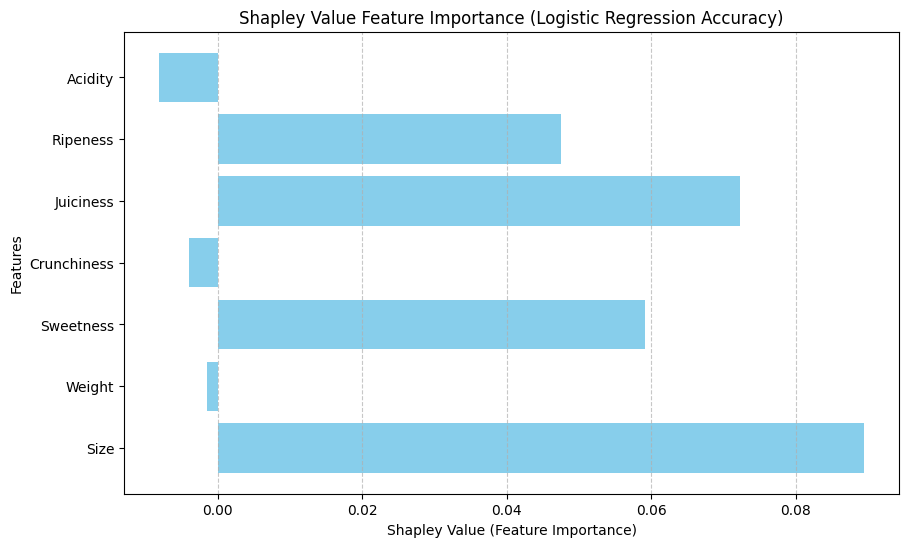

In [16]:
import itertools
import pandas as pd
import statsmodels.api as sm
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

df = pd.read_csv(r"/Users/rohitsuresh/Documents/IISC/Explainable-AI--Cooperative-Game-Theory-main/data/apple_quality.csv")
df= df.drop('A_id',axis=1)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
# Replace any infinite values with NaN and drop rows containing NaN values
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Convert the 'Quality' column to binary: 0 if 'bad' and 1 if 'good'
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})


X = df.drop(columns=["Quality"])
Y = df["Quality"]


# 4. Split data into training and testing sets (80% train, 20% test)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# Get a list of feature names from the training set
feature_names = list(X_train.columns)

# 5. Define a function to compute accuracy for a given subset of features using logistic regression
def compute_accuracy(subset):
    # If the subset is empty, use a constant-only model
    if len(subset) == 0:
        X_train_subset = sm.add_constant(pd.DataFrame(index=X_train.index))
        X_test_subset = sm.add_constant(pd.DataFrame(index=X_test.index))
    else:
        X_train_subset = X_train[list(subset)]
        X_train_subset = sm.add_constant(X_train_subset)
        X_test_subset = X_test[list(subset)]
        X_test_subset = sm.add_constant(X_test_subset, has_constant='add')

    # Fit logistic regression on the training subset
    model = sm.Logit(Y_train, X_train_subset).fit(disp=0)
    # Predict probabilities on the test set
    pred_probs = model.predict(X_test_subset)
    # Convert probabilities to binary predictions (using threshold = 0.5)
    preds = (pred_probs > 0.5).astype(int)
    # Compute accuracy on the test set
    acc = accuracy_score(Y_test, preds)
    return acc

# 6. Compute accuracy for all possible feature subsets (including the empty set)
accuracy_values = {}
for r in range(len(feature_names) + 1):
    for subset in itertools.combinations(feature_names, r):
        accuracy_values[frozenset(subset)] = compute_accuracy(subset)

print("Subset accuracies:")
print(accuracy_values)

# 7. Compute Shapley values for each feature based on the accuracy metric
shapley_values = {feature: 0 for feature in feature_names}
n = len(feature_names)

for feature in feature_names:
    shapley_sum = 0
    # Consider every subset of features not containing the current feature
    for r in range(n):
        for subset in itertools.combinations([f for f in feature_names if f != feature], r):
            subset = frozenset(subset)
            # Calculate the marginal contribution of the feature when added to the subset
            acc_with_feature = accuracy_values[subset | {feature}]
            acc_without_feature = accuracy_values[subset]
            marginal_contribution = acc_with_feature - acc_without_feature
            # Weight for the subset per the Shapley formula
            weight = (np.math.factorial(len(subset)) * np.math.factorial(n - len(subset) - 1)) / np.math.factorial(n)
            shapley_sum += weight * marginal_contribution
    shapley_values[feature] = shapley_sum

# 8. Convert Shapley values to a DataFrame for visualization and display the results
shapley_df = pd.DataFrame(list(shapley_values.items()), columns=["Feature", "Shapley Value"])
print("\nShapley Value Feature Importance:")
print(shapley_df)

# 9. Plot the Shapley values as a horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(shapley_df["Feature"], shapley_df["Shapley Value"], color='skyblue')
plt.xlabel("Shapley Value (Feature Importance)")
plt.ylabel("Features")
plt.title("Shapley Value Feature Importance (Logistic Regression Accuracy)")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()


Banzhaf Value Feature Importance:
       Feature  Banzhaf Value
0         Size       0.079648
1       Weight       0.001680
2    Sweetness       0.053633
3  Crunchiness      -0.001094
4    Juiciness       0.066875
5     Ripeness       0.039570
6      Acidity      -0.002383


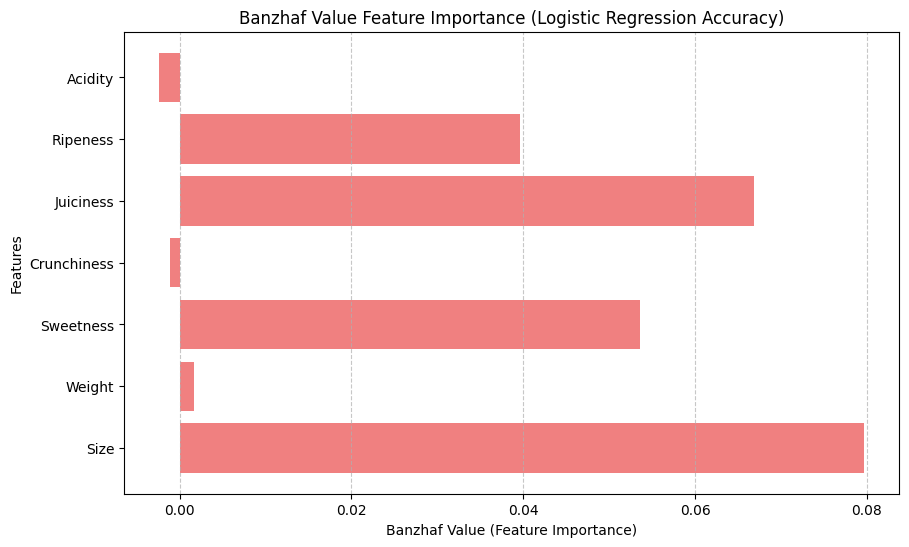

In [17]:
banzhaf_values = {feature: 0 for feature in feature_names}
n = len(feature_names)

for feature in feature_names:
    marginal_contributions = []
    subsets_without_feature = itertools.chain.from_iterable(
        itertools.combinations([f for f in feature_names if f != feature], r) for r in range(n)
    )

    for subset in subsets_without_feature:
        subset = frozenset(subset)
        acc_with_feature = accuracy_values[subset | {feature}]
        acc_without_feature = accuracy_values[subset]


        marginal_contribution = acc_with_feature - acc_without_feature
        marginal_contributions.append(marginal_contribution)

    # Normalize correctly using Banzhaf formula
    banzhaf_values[feature] = sum(marginal_contributions) / (2 ** (n - 1))

# Display results
banzhaf_df = pd.DataFrame(list(banzhaf_values.items()), columns=["Feature", "Banzhaf Value"])
print("\nBanzhaf Value Feature Importance:")
print(banzhaf_df)

# Plotting
plt.figure(figsize=(10, 6))
plt.barh(banzhaf_df["Feature"], banzhaf_df["Banzhaf Value"], color='lightcoral')
plt.xlabel("Banzhaf Value (Feature Importance)")
plt.ylabel("Features")
plt.title("Banzhaf Value Feature Importance (Logistic Regression Accuracy)")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

Shapley–Shubik Index Feature Importance:
       Feature  Shapley-Shubik Index
0         Size              0.310317
1       Weight              0.026190
2    Sweetness              0.028571
3  Crunchiness              0.002381
4    Juiciness              0.322222
5     Ripeness              0.310317
6      Acidity              0.000000


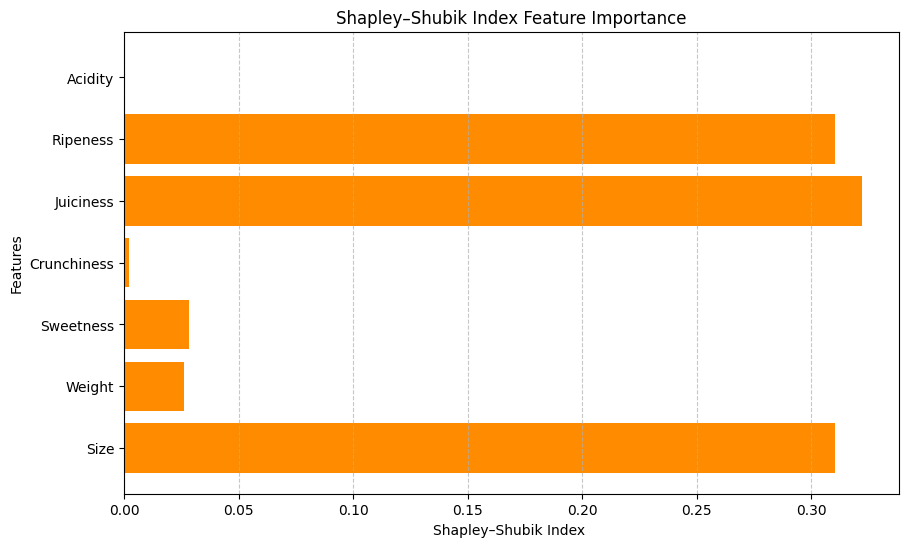

In [6]:
accuracy_threshold = 0.6

# Initialize counts for each feature
shapley_shubik_counts = {feature: 0 for feature in feature_names}
permutations = list(itertools.permutations(feature_names))
total_permutations = len(permutations)

# Iterate through all permutations
for perm in permutations:
    subset = set()
    for feature in perm:
        prev_accuracy = compute_accuracy(subset)
        subset.add(feature)
        curr_accuracy = compute_accuracy(subset)

        if np.isnan(curr_accuracy) or np.isnan(prev_accuracy):
            continue

        # Classical Shapley-Shubik: pivotal when threshold is crossed
        if prev_accuracy < accuracy_threshold <= curr_accuracy:
            shapley_shubik_counts[feature] += 1
            break

# Normalize by total permutations
shapley_shubik_index = {
    feature: count / total_permutations for feature, count in shapley_shubik_counts.items()
}

# Create DataFrame of results
shapley_shubik_df = pd.DataFrame(
    shapley_shubik_index.items(), columns=["Feature", "Shapley-Shubik Index"]
)

# Display results
print("Shapley–Shubik Index Feature Importance:")
print(shapley_shubik_df)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(shapley_shubik_df["Feature"], shapley_shubik_df["Shapley-Shubik Index"], color='darkorange')
plt.xlabel("Shapley–Shubik Index ")
plt.ylabel("Features")
plt.title("Shapley–Shubik Index Feature Importance")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

       Feature  Nucleolus Value
0         Size         0.103609
1       Weight         0.063565
2    Sweetness         0.111437
3  Crunchiness         0.103376
4    Juiciness         0.156157
5     Ripeness         0.133683
6      Acidity         0.097183


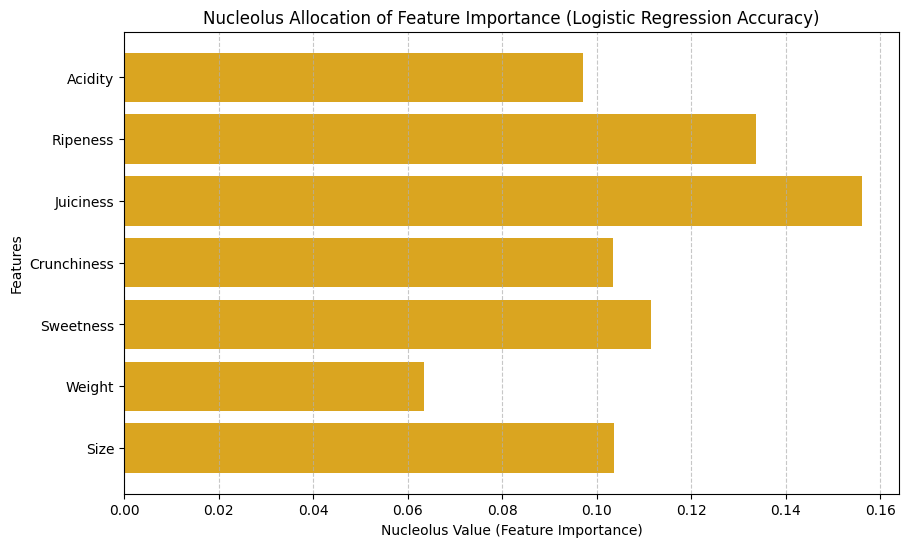

In [7]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Step 1: Compute pro-rata imputation using the accuracy metric
total_value = sum(accuracy_values[frozenset({f})] for f in feature_names)
full_coalition_value = accuracy_values[frozenset(feature_names)]

initial_x = {
    feature: (accuracy_values[frozenset({feature})] / total_value) * full_coalition_value
    for feature in feature_names
}

# Step 2: (Optional) Assign feature worth to all coalitions containing it
coalition_values = {
    S: sum(initial_x.get(f, 0) for f in S)
    for S in accuracy_values.keys() if S
}

# Step 3: Compute the excess for each coalition.
# Excess is the difference between the coalition’s accuracy value and the sum of the current allocations for its features.
def compute_excess(S, x_values):
    subset_excess = []
    # Iterate over all non-empty subcoalitions T of S.
    for r in range(1, len(S) + 1):
        for T in itertools.combinations(S, r):
            T = frozenset(T)
            if T in accuracy_values and T:
                excess = accuracy_values[T] - sum(x_values.get(f, 0) for f in T)
                subset_excess.append(excess)
    return max(subset_excess) if subset_excess else 0

excess_values = {S: compute_excess(S, initial_x) for S in accuracy_values.keys() if S}

# Step 4: Iteratively adjust the allocations to minimize the excess,
# aiming to find the nucleolus allocation for feature importance.
x = initial_x.copy()
max_iterations = 1000
iteration = 0

while any(excess_values[S] > accuracy_values[S] / (len(S) + 1) for S in excess_values) and iteration < max_iterations:
    for S in excess_values:
        for feature in S:
            x[feature] += (accuracy_values[S] - sum(x.get(f, 0) for f in S)) / (len(S) + 1)
        # Recalculate the excess for coalition S after the update.
        excess_values[S] = compute_excess(S, x)
    iteration += 1

nucleolus_df = pd.DataFrame(list(x.items()), columns=["Feature", "Nucleolus Value"])
print(nucleolus_df)

# Plot the nucleolus values as a horizontal bar chart.
plt.figure(figsize=(10, 6))
plt.barh(nucleolus_df["Feature"], nucleolus_df["Nucleolus Value"], color='goldenrod')
plt.xlabel("Nucleolus Value (Feature Importance)")
plt.ylabel("Features")
plt.title("Nucleolus Allocation of Feature Importance (Logistic Regression Accuracy)")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

Single-feature claims (accuracy on test set):
  Size: 0.6138
  Weight: 0.4575
  Sweetness: 0.5875
  Crunchiness: 0.4700
  Juiciness: 0.6188
  Ripeness: 0.6150
  Acidity: 0.4612

Proportional feature importance (CPI):
  Size: 0.1124
  Weight: 0.0838
  Sweetness: 0.1076
  Crunchiness: 0.0860
  Juiciness: 0.1133
  Ripeness: 0.1126
  Acidity: 0.0844


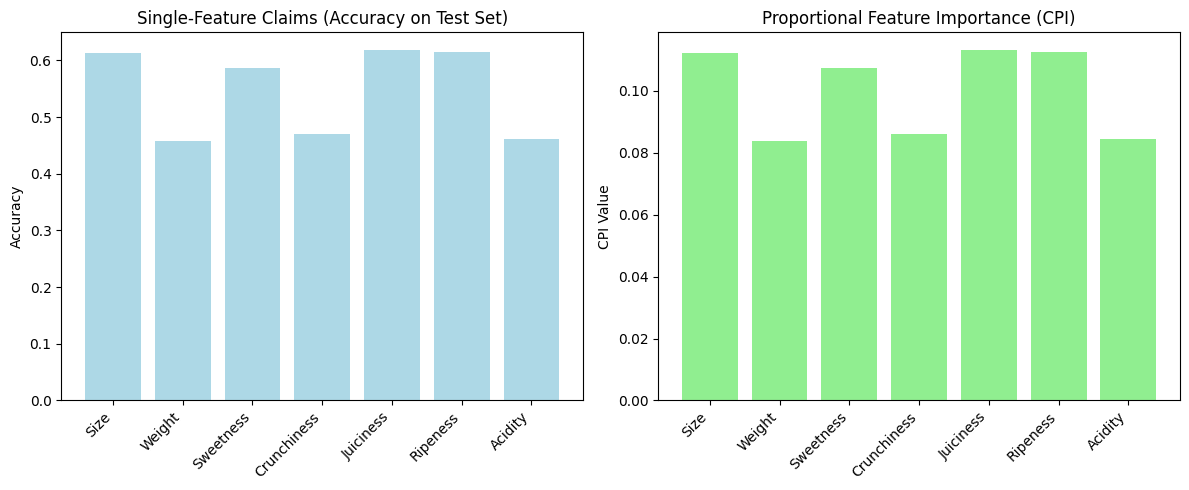

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# 1. Load and prepare the data
df = pd.read_csv(r"/Users/rohitsuresh/Documents/IISC/Explainable-AI--Cooperative-Game-Theory-main/data/apple_quality.csv")

# Drop the identifier column if it exists
if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

# Convert non-target columns to numeric, replace infinities, and drop missing values
for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Convert the 'Quality' column to binary: 0 if 'bad' and 1 if 'good'
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

# Define features and target variable
X = df.drop(columns=['Quality'])
y = df['Quality']

# 2. Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Compute single-feature claims using test set p
claims = []
feature_names = X.columns.tolist()

for feature in feature_names:
    # Select only the current feature for training and testing
    X_train_single = X_train[[feature]]
    X_test_single = X_test[[feature]]

    # Fit a logistic regression model using only this feature
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train_single, y_train)

    # Predict on the test set and compute accuracy
    y_pred = model.predict(X_test_single)
    c_i = accuracy_score(y_test, y_pred)
    claims.append(c_i)

# 4. Compute the sum of claims
total_claims = sum(claims)

# 5. Choose an endowment E and compute the proportionality factor lambda
E = 0.7
lambda_ = E / total_claims if total_claims != 0 else 0

# 6. Compute Proportional Feature Importance (CPI) for each feature
cpi_values = [lambda_ * c_i for c_i in claims]
cpi_importance = dict(zip(feature_names, cpi_values))

# 7. Print the results
print("Single-feature claims (accuracy on test set):")
for feature, claim in zip(feature_names, claims):
    print(f"  {feature}: {claim:.4f}")

print("\nProportional feature importance (CPI):")
for feature, cpi in cpi_importance.items():
    print(f"  {feature}: {cpi:.4f}")

# 8. Plot single-feature claims and CPI values
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# Left plot: Single-feature claims (accuracy)
axes[0].bar(feature_names, claims, color='lightblue')
axes[0].set_title('Single-Feature Claims (Accuracy on Test Set)')
axes[0].set_ylabel('Accuracy')
axes[0].set_xticklabels(feature_names, rotation=45, ha='right')

# Right plot: CPI values
axes[1].bar(feature_names, cpi_values, color='lightgreen')
axes[1].set_title('Proportional Feature Importance (CPI)')
axes[1].set_ylabel('CPI Value')
axes[1].set_xticklabels(feature_names, rotation=45, ha='right')

plt.tight_layout()
plt.show()

Single-feature claims (Accuracy on test set):
  Size: 0.6138
  Weight: 0.4575
  Sweetness: 0.5875
  Crunchiness: 0.4700
  Juiciness: 0.6188
  Ripeness: 0.6150
  Acidity: 0.4612

Total Endowment (E) = 0.3200

Constrained Equal Awards (CEqA) Feature Importance:
  Size: 0.0457
  Weight: 0.0457
  Sweetness: 0.0457
  Crunchiness: 0.0457
  Juiciness: 0.0457
  Ripeness: 0.0457
  Acidity: 0.0457


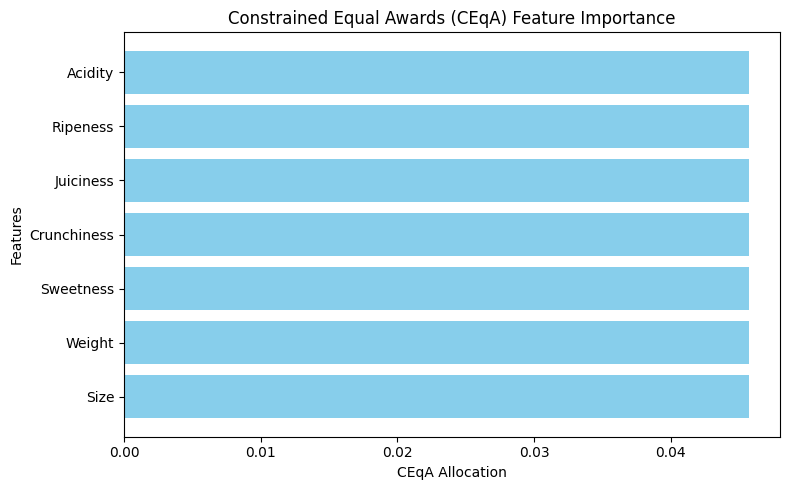

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import itertools

def compute_ceqa(claims, E):
    """
    Computes the Constrained Equal Awards (CEqA) allocation for a set of claims
    given a total endowment E.

    Parameters:
    -----------
    claims : list or array-like
        A list of claims c_i (e.g., single-feature performances).
    E : float
        The total endowment to distribute.

    Returns:
    --------
    awards : list
        A list of CEqA awards for each claim in the same order as 'claims'.
    """
    # Convert claims to a NumPy array for convenience
    c_array = np.array(claims, dtype=float)
    n = len(c_array)

    # If the sum of claims is less than or equal to E, everyone is "fully paid"
    if np.sum(c_array) <= E:
        return c_array.tolist()

    # Otherwise, find μ such that sum(min(c_i, μ)) = E.
    # Sort claims but keep track of original indices
    sorted_indices = np.argsort(c_array)
    c_sorted = c_array[sorted_indices]

    partial_sum = 0.0
    for i in range(n):
        share = (E - partial_sum) / (n - i)
        if c_sorted[i] <= share:
            partial_sum += c_sorted[i]
        else:
            mu = share
            final_sorted_awards = []
            for j in range(i):
                final_sorted_awards.append(c_sorted[j])
            for j in range(i, n):
                final_sorted_awards.append(mu)
            awards = [0.0] * n
            for idx, sorted_idx in enumerate(sorted_indices):
                awards[sorted_idx] = final_sorted_awards[idx]
            return awards
    return c_array.tolist()

# 1. Load and prepare the apple quality data
df = pd.read_csv(r"/Users/rohitsuresh/Documents/IISC/Explainable-AI--Cooperative-Game-Theory-main/data/apple_quality.csv")

# Drop the identifier column if it exists
if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

# Convert non-target columns to numeric
for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Convert the 'Quality' column to binary: 0 for 'bad', 1 for 'good'
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

# 2. Split data into training and testing sets (80% train, 20% test)
X = df.drop(columns=['Quality'])
y = df['Quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Compute single-feature claims (accuracy on test set using logistic regression)
feature_names = X.columns.tolist()
claims = []

for feature in feature_names:
    # Use only one feature at a time
    X_train_single = X_train[[feature]]
    X_test_single = X_test[[feature]]

    model = LogisticRegression(solver='liblinear')
    model.fit(X_train_single, y_train)

    y_pred = model.predict(X_test_single)
    c_i = accuracy_score(y_test, y_pred)
    claims.append(c_i)

E = 0.32


ceqa_awards = compute_ceqa(claims, E)

print("Single-feature claims (Accuracy on test set):")
for f, c in zip(feature_names, claims):
    print(f"  {f}: {c:.4f}")

print(f"\nTotal Endowment (E) = {E:.4f}\n")

print("Constrained Equal Awards (CEqA) Feature Importance:")
for f, award in zip(feature_names, ceqa_awards):
    print(f"  {f}: {award:.4f}")

# 7. Plot CEqA allocations
plt.figure(figsize=(8, 5))
plt.barh(feature_names, ceqa_awards, color='skyblue')
plt.xlabel('CEqA Allocation')
plt.ylabel('Features')
plt.title('Constrained Equal Awards (CEqA) Feature Importance')
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

def compute_ceql(claims, E):

    c_array = np.array(claims, dtype=float)
    total_claims = np.sum(c_array)

    # If total claims are less than or equal to E, return claims as is.
    if total_claims <= E:
        return c_array.tolist()

    # Otherwise, find r such that sum(max(0, c_i - r)) = E via binary search.
    lo, hi = 0.0, np.max(c_array)

    for _ in range(100):  # 100 iterations for sufficient precision
        mid = (lo + hi) / 2.0
        current_sum = np.sum(np.maximum(0, c_array - mid))

        if current_sum > E:
            lo = mid
        else:
            hi = mid

    r = (lo + hi) / 2.0
    final_allocations = np.maximum(0, c_array - r)

    return final_allocations.tolist()


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

# Drop the identifier column if present
if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

# Convert non-target columns to numeric, replace infinities, and drop missing values
for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Map the 'Quality' column to binary: 0 for 'bad', 1 for 'good'
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})


X = df.drop(columns=['Quality'])
y = df['Quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


feature_names = X.columns.tolist()
claims = []

for feature in feature_names:
    X_train_single = X_train[[feature]]
    X_test_single = X_test[[feature]]

    model = LogisticRegression(solver='liblinear')
    model.fit(X_train_single, y_train)

    y_pred = model.predict(X_test_single)
    c_i = accuracy_score(y_test, y_pred)
    claims.append(c_i)


E = 0.7


ceql_allocations = compute_ceql(claims, E)


print("Single-feature claims (Accuracy on test set):")
for f, c in zip(feature_names, claims):
    print(f"  {f}: {c:.4f}")

print(f"\nTotal Endowment (E) = {E:.2f}\n")

print("Constrained Equal Losses (CEqL) Allocations:")
for f, alloc in zip(feature_names, ceql_allocations):
    print(f"  {f}: {alloc:.4f}")

plt.figure(figsize=(8, 5))
plt.barh(feature_names, ceql_allocations, color='lightcoral')
plt.xlabel('CEqL Allocation')
plt.ylabel('Features')
plt.title('Constrained Equal Losses (CEqL) Feature Importance')
plt.gca().invert_yaxis()  # Optional: place the first feature at the top
plt.tight_layout()
plt.show()

Single-feature claims (Accuracy on test set):
  Size: 0.6138
  Weight: 0.4575
  Sweetness: 0.5875
  Crunchiness: 0.4700
  Juiciness: 0.6188
  Ripeness: 0.6150
  Acidity: 0.4612

Total Endowment (E) = 0.70

Conflicting Claims Talmud Valuation (CCTV) Allocations:
  Size: 0.1000
  Weight: 0.1000
  Sweetness: 0.1000
  Crunchiness: 0.1000
  Juiciness: 0.1000
  Ripeness: 0.1000
  Acidity: 0.1000


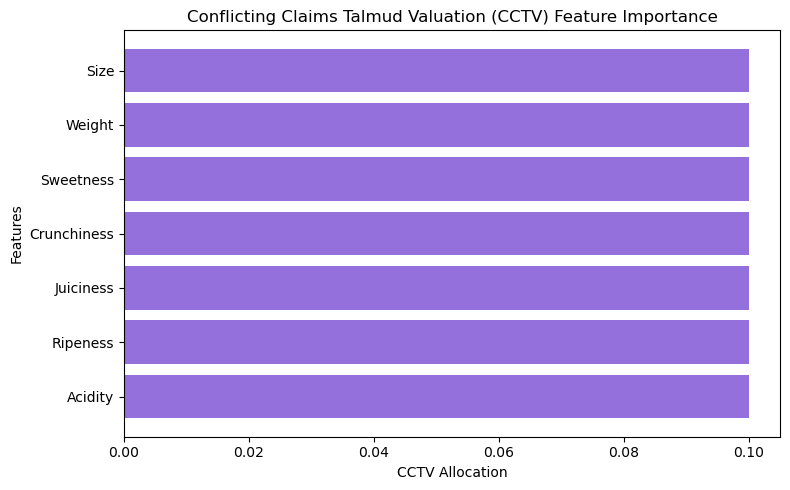

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

def compute_ceqa(claims, E):

    c_array = np.array(claims, dtype=float)
    total_claims = np.sum(c_array)

    # If total claims <= E, everyone gets full claim
    if total_claims <= E:
        return c_array.tolist()

    # Sort claims in ascending order
    sorted_indices = np.argsort(c_array)
    c_sorted = c_array[sorted_indices]

    partial_sum = 0.0
    n = len(c_array)
    i = 0

    while i < n:
        remaining = n - i
        share = (E - partial_sum) / remaining
        if c_sorted[i] <= share:
            partial_sum += c_sorted[i]
            i += 1
        else:
            mu = share
            break


    if i == n:
        final_sorted_awards = c_sorted
    else:
        mu = (E - partial_sum) / (n - i)
        final_sorted_awards = np.empty(n, dtype=float)
        final_sorted_awards[:i] = c_sorted[:i]  # fully paid
        final_sorted_awards[i:] = mu           # capped at mu

    # Re-map to original order
    awards = np.empty(n, dtype=float)
    for j, idx in enumerate(sorted_indices):
        awards[idx] = final_sorted_awards[j]

    return awards.tolist()

def compute_ceql(claims, E):

    c_array = np.array(claims, dtype=float)
    total_claims = np.sum(c_array)

    # If sum of claims <= E, no reduction needed
    if total_claims <= E:
        return c_array.tolist()

    # Otherwise, binary search for r
    lo, hi = 0.0, np.max(c_array)

    for _ in range(100):
        mid = (lo + hi) / 2.0
        current_sum = np.sum(np.maximum(0, c_array - mid))

        if current_sum > E:
            lo = mid
        else:
            hi = mid

    r = (lo + hi) / 2.0
    final_allocations = np.maximum(0, c_array - r)
    return final_allocations.tolist()

def compute_cctv(claims, E):

    c_array = np.array(claims, dtype=float)
    half_claims = c_array / 2.0
    H = np.sum(half_claims)

    if E <= H:
        # Returns a list
        cctv_allocations = compute_ceqa(half_claims, E)
    else:
        leftover = E - H
        ceql_result = compute_ceql(half_claims, leftover)  # list
        half_claims_list = half_claims.tolist()
        cctv_allocations = [h + l for h, l in zip(half_claims_list, ceql_result)]

    return cctv_allocations


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")


if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

# Convert non-target columns to numeric and handle infinities/missing values
for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Map 'Quality' to binary: 0 for 'bad', 1 for 'good'
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})


X = df.drop(columns=['Quality'])
y = df['Quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


feature_names = X.columns.tolist()
claims = []

for feature in feature_names:
    # Use one feature at a time
    X_train_single = X_train[[feature]]
    X_test_single = X_test[[feature]]

    model = LogisticRegression(solver='liblinear')
    model.fit(X_train_single, y_train)

    y_pred = model.predict(X_test_single)
    c_i = accuracy_score(y_test, y_pred)
    claims.append(c_i)


E = 0.7  # Example endowment


cctv_allocations = compute_cctv(claims, E)


print("Single-feature claims (Accuracy on test set):")
for f, c in zip(feature_names, claims):
    print(f"  {f}: {c:.4f}")

print(f"\nTotal Endowment (E) = {E:.2f}\n")

print("Conflicting Claims Talmud Valuation (CCTV) Allocations:")
for f, alloc in zip(feature_names, cctv_allocations):
    print(f"  {f}: {alloc:.4f}")


plt.figure(figsize=(8, 5))
plt.barh(feature_names, cctv_allocations, color='mediumpurple')
plt.xlabel('CCTV Allocation')
plt.ylabel('Features')
plt.title('Conflicting Claims Talmud Valuation (CCTV) Feature Importance')
plt.gca().invert_yaxis()  # Optional: place the first feature at the top
plt.tight_layout()
plt.show()

Single-feature claims (Accuracy on test set):
  Size: 0.6138
  Weight: 0.4575
  Sweetness: 0.5875
  Crunchiness: 0.4700
  Juiciness: 0.6188
  Ripeness: 0.6150
  Acidity: 0.4612

Total Endowment (E) = 0.70

Conflicting Claims Random Arrival (CCRA) Allocations:
  Size: 0.1112
  Weight: 0.0852
  Sweetness: 0.1069
  Crunchiness: 0.0873
  Juiciness: 0.1121
  Ripeness: 0.1115
  Acidity: 0.0858


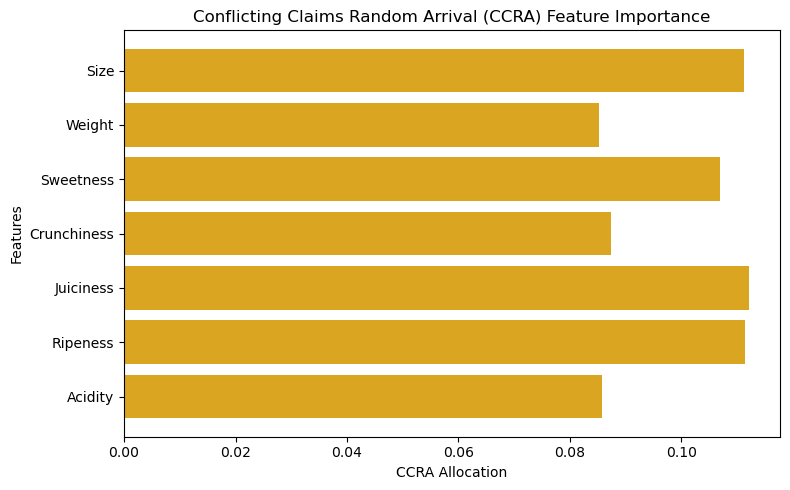

In [ ]:
import pandas as pd
import numpy as np
from itertools import permutations
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import math

def compute_ccra(claims, E):

    c_array = np.array(claims, dtype=float)
    n = len(c_array)

    # Prepare an accumulator V_i for each feature
    V = np.zeros(n, dtype=float)

    # Generate all permutations of indices
    all_indices = range(n)
    perm_count = math.factorial(n)  # total number of permutations

    for perm in permutations(all_indices):
        E_temp = E
        for idx in perm:
            award = min(c_array[idx], E_temp)
            V[idx] += award
            E_temp -= award
            if E_temp <= 0:
                break  # no more endowment left

    # Average each V_i over all permutations
    RA = V / perm_count
    return RA.tolist()


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

# Drop the identifier column if it exists
if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

# Convert non-target columns to numeric, handle infinities, and drop missing values
for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Map 'Quality' to binary: 0 for 'bad', 1 for 'good'
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})


X = df.drop(columns=['Quality'])
y = df['Quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


feature_names = X.columns.tolist()
claims = []

for feature in feature_names:
    # Use only one feature at a time
    X_train_single = X_train[[feature]]
    X_test_single = X_test[[feature]]

    model = LogisticRegression(solver='liblinear')
    model.fit(X_train_single, y_train)

    y_pred = model.predict(X_test_single)
    c_i = accuracy_score(y_test, y_pred)
    claims.append(c_i)


E = 0.7


ccra_allocations = compute_ccra(claims, E)


print("Single-feature claims (Accuracy on test set):")
for f, c in zip(feature_names, claims):
    print(f"  {f}: {c:.4f}")

print(f"\nTotal Endowment (E) = {E:.2f}\n")

print("Conflicting Claims Random Arrival (CCRA) Allocations:")
for f, alloc in zip(feature_names, ccra_allocations):
    print(f"  {f}: {alloc:.4f}")


plt.figure(figsize=(8, 5))
plt.barh(feature_names, ccra_allocations, color='goldenrod')
plt.xlabel('CCRA Allocation')
plt.ylabel('Features')
plt.title('Conflicting Claims Random Arrival (CCRA) Feature Importance')
plt.gca().invert_yaxis()  # Optional: place the first feature at the top
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# Load and preprocess the dataset
df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")
df = df.drop('A_id', axis=1)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

X = df.drop(columns=["Quality"])
y = df["Quality"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Predict the majority class from training labels
majority_class = y_train.mode()[0]

# Predict this constant value for all test samples
y_pred_zero_feature = [majority_class] * len(y_test)

# Compute accuracy
accuracy_zero_feature = accuracy_score(y_test, y_pred_zero_feature)

print(f"Accuracy with ZERO FEATURES (majority class = {majority_class}): {accuracy_zero_feature:.4f}")

🎯 Accuracy with ZERO FEATURES (majority class = 1): 0.4988


Computed d* (common disruption): 0.1857

Gately Feature Importance Allocations (Test Accuracy Shares):
  Size: 0.1731
  Weight: 0.0843
  Sweetness: 0.1278
  Crunchiness: 0.0747
  Juiciness: 0.1317
  Ripeness: 0.0995
  Acidity: 0.0627


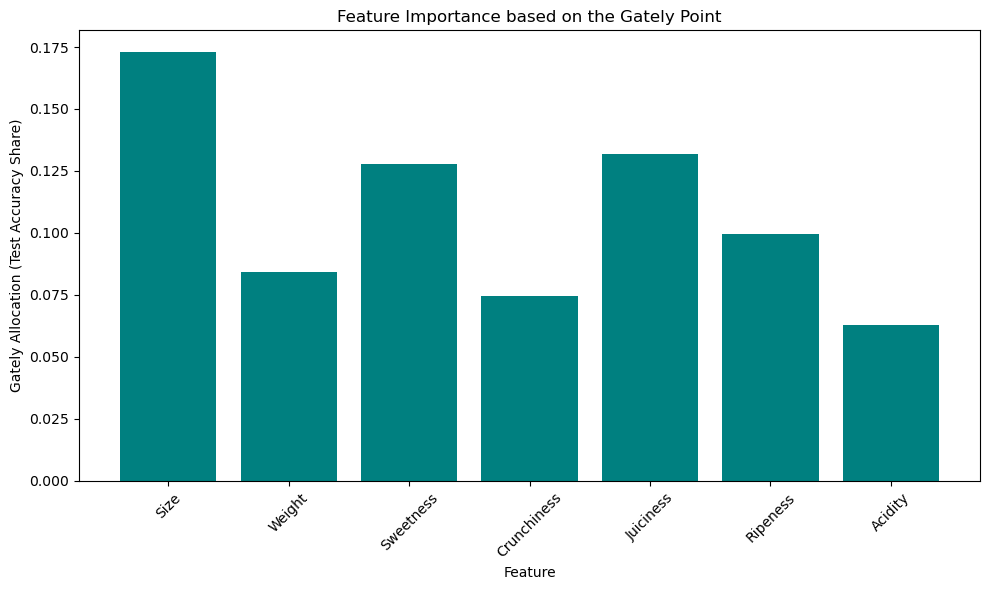

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

# Drop the identifier column if it exists
if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

# Convert non-target columns to numeric, replace infinities, and drop missing values
for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Map 'Quality' to binary: 0 for 'bad', 1 for 'good'
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})


target = "Quality"
features = [col for col in df.columns if col != target]
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


def compute_accuracy(feature_subset):


    model = LogisticRegression(solver='liblinear')
    model.fit(X_train[feature_subset], y_train)
    y_pred = model.predict(X_test[feature_subset])
    return accuracy_score(y_test, y_pred)


vN = compute_accuracy(features)

v_single = {}
v_without = {}

for feat in features:
    v_single[feat] = compute_accuracy([feat])
    remaining_features = [f for f in features if f != feat]
    v_without[feat] = compute_accuracy(remaining_features)


n = len(features)
numerator = (n - 1) * vN - sum(v_without[feat] for feat in features)
denom = vN - sum(v_single[feat] for feat in features)

if np.isclose(denom, 0):
    raise ValueError("The denominator is zero; cannot compute d*.")

d_star = numerator / denom

if np.isclose(d_star, -1):
    raise ValueError("d* is -1; the Gately point cannot be computed.")

print(f"Computed d* (common disruption): {d_star:.4f}")


gately_allocation = {}
for feat in features:
    M_i = vN - v_without[feat]  # The marginal contribution of feature i.
    x_i = (M_i + d_star * v_single[feat]) / (d_star + 1)
    gately_allocation[feat] = x_i


print("\nGately Feature Importance Allocations (Test Accuracy Shares):")
for feat, alloc in gately_allocation.items():
    print(f"  {feat}: {alloc:.4f}")

plt.figure(figsize=(10, 6))
plt.bar(gately_allocation.keys(), gately_allocation.values(), color='teal')
plt.xlabel("Feature")
plt.ylabel("Gately Allocation (Test Accuracy Share)")
plt.title("Feature Importance based on the Gately Point")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

v(full): 0.75375
Individual values: [0.61375, 0.4575, 0.5875, 0.47, 0.61875, 0.615, 0.46125]
Initial allocation: [0.10767857142857143, 0.10767857142857143, 0.10767857142857143, 0.10767857142857143, 0.10767857142857143, 0.10767857142857143, 0.10767857142857143]
No further transfer possible without violating individual rationality; stopping.

Final feature importance allocation: [0.10767857 0.10767857 0.10767857 0.10767857 0.10767857 0.10767857
 0.10767857]
Number of iterations: 0
Final delta: 0.11392857142857143


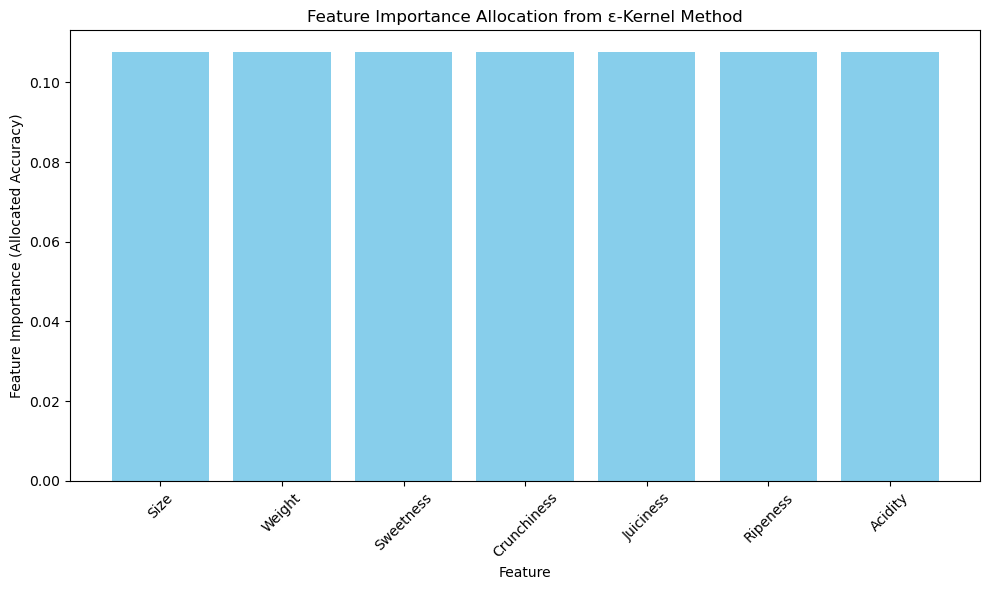

In [ ]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split


def all_coalitions(n):

    features = list(range(n))
    coalitions = []
    for r in range(1, n+1):
        for subset in itertools.combinations(features, r):
            coalitions.append(frozenset(subset))
    return coalitions

def compute_value(coalition, X_train, X_test, y_train, y_test):

    if len(coalition) == 0:
        return 0.0  # By convention, the empty coalition has zero value.
    cols = list(coalition)
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train[:, cols], y_train)
    y_pred = model.predict(X_test[:, cols])
    return accuracy_score(y_test, y_pred)

def compute_surplus(x, i, j, v_dict):

    best = -np.inf
    for coalition, value in v_dict.items():
        if i in coalition and j not in coalition:
            payoff_sum = sum(x[k] for k in coalition)
            surplus = value - payoff_sum
            if surplus > best:
                best = surplus
    return best

def epsilon_kernel(x_init, v_dict, epsilon, v_full, individual_values, n):


    x = np.array(x_init, dtype=float)
    max_iter = 10000
    for iteration in range(max_iter):
        delta = 0
        chosen_pair = None


        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                s_ij = compute_surplus(x, i, j, v_dict)
                s_ji = compute_surplus(x, j, i, v_dict)
                diff = s_ij - s_ji
                if diff > delta:
                    delta = diff
                    chosen_pair = (i, j)

        # Check termination condition
        if delta <= epsilon * v_full:
            print(f"Converged after {iteration} iterations with delta = {delta:.4f}")
            break

        if chosen_pair is None:
            print("No eligible pair found; stopping.")
            break

        i_star, j_star = chosen_pair

        # Ensure that the transfer does not violate individual rationality:
        # Maximum transferable amount is x[j_star] - v({j_star})
        max_transfer = x[j_star] - individual_values[j_star]
        d = min(delta / 2, max_transfer)
        if d <= 0:
            print("No further transfer possible without violating individual rationality; stopping.")
            break

        # Perform the side-payment: transfer d from j_star to i_star
        x[i_star] += d
        x[j_star] -= d

    return x, iteration, delta


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

# Drop the identifier column if it exists.
if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

# Convert non-target columns to numeric; replace infinities and drop missing values.
for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Map 'Quality' to binary: 0 for 'bad', 1 for 'good'
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})


target_column = "Quality"
feature_columns = [col for col in df.columns if col != target_column]
X_full = df[feature_columns].values
y_full = df[target_column].values

# Use an 80/20 split.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=42)

n_features = X_train.shape[1]


coalitions = all_coalitions(n_features)

# Compute v(C) for each coalition using the test-set accuracy of a logistic regression model.
v_dict = {}
for coalition in coalitions:
    v_val = compute_value(coalition, X_train, X_test, y_train, y_test)
    v_dict[coalition] = v_val

# Full coalition: all features.
full_coalition = frozenset(range(n_features))
v_full = v_dict[full_coalition]

# Compute individual values: v({i}) for each feature i.
individual_values = []
for i in range(n_features):
    indiv = frozenset([i])
    individual_values.append(v_dict[indiv])

print("v(full):", v_full)
print("Individual values:", individual_values)


# Initial allocation: equally divide v(full) among features.
x_init = [v_full / n_features] * n_features
print("Initial allocation:", x_init)

# Set the tolerance parameter epsilon (adjust as needed).
epsilon = 0.01

# Run the ε-Kernel transfer scheme to compute feature importance.
x_final, iterations, final_delta = epsilon_kernel(x_init, v_dict, epsilon, v_full, individual_values, n_features)

print("\nFinal feature importance allocation:", x_final)
print("Number of iterations:", iterations)
print("Final delta:", final_delta)


plt.figure(figsize=(10, 6))
plt.bar(feature_columns, x_final, color='skyblue')
plt.xlabel('Feature')
plt.ylabel('Feature Importance (Allocated Accuracy)')
plt.title('Feature Importance Allocation from ε-Kernel Method')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

v(full): 0.75375
Individual values: [0.61375, 0.4575, 0.5875, 0.47, 0.61875, 0.615, 0.46125]
Smart initialization (normalized individual values): [0.12098439032363517, 0.09018388362209873, 0.11580990519777706, 0.09264792415822164, 0.12197000653808436, 0.12123079437724747, 0.0909230957829356]
No further transfer possible without violating individual rationality; stopping.

Final feature importance allocation: [0.12098439 0.09018388 0.11580991 0.09264792 0.12197001 0.12123079
 0.0909231 ]
Number of iterations: 0
Final delta: 0.09618747956848639


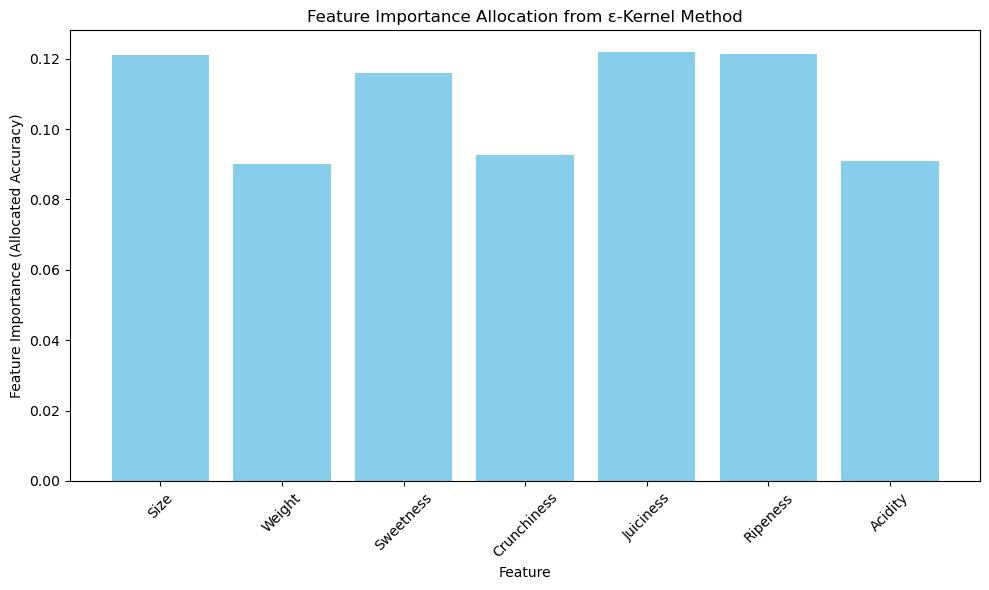

In [ ]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split


def all_coalitions(n):
    features = list(range(n))
    coalitions = []
    for r in range(1, n+1):
        for subset in itertools.combinations(features, r):
            coalitions.append(frozenset(subset))
    return coalitions

def compute_value(coalition, X_train, X_test, y_train, y_test):
    if len(coalition) == 0:
        return 0.0
    cols = list(coalition)
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train[:, cols], y_train)
    y_pred = model.predict(X_test[:, cols])
    return accuracy_score(y_test, y_pred)

def compute_surplus(x, i, j, v_dict):
    best = -np.inf
    for coalition, value in v_dict.items():
        if i in coalition and j not in coalition:
            payoff_sum = sum(x[k] for k in coalition)
            surplus = value - payoff_sum
            if surplus > best:
                best = surplus
    return best

def epsilon_kernel(x_init, v_dict, epsilon, v_full, individual_values, n):
    x = np.array(x_init, dtype=float)
    max_iter = 10000
    for iteration in range(max_iter):
        delta = 0
        chosen_pair = None

        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                s_ij = compute_surplus(x, i, j, v_dict)
                s_ji = compute_surplus(x, j, i, v_dict)
                diff = s_ij - s_ji
                if diff > delta:
                    delta = diff
                    chosen_pair = (i, j)

        if delta <= epsilon * v_full:
            print(f"Converged after {iteration} iterations with delta = {delta:.4f}")
            break

        if chosen_pair is None:
            print("No eligible pair found; stopping.")
            break

        i_star, j_star = chosen_pair
        max_transfer = x[j_star] - individual_values[j_star]
        d = min(delta / 2, max_transfer)
        if d <= 0:
            print("No further transfer possible without violating individual rationality; stopping.")
            break

        x[i_star] += d
        x[j_star] -= d

    return x, iteration, delta


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})


target_column = "Quality"
feature_columns = [col for col in df.columns if col != target_column]
X_full = df[feature_columns].values
y_full = df[target_column].values

X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=42)
n_features = X_train.shape[1]


coalitions = all_coalitions(n_features)

v_dict = {}
for coalition in coalitions:
    v_val = compute_value(coalition, X_train, X_test, y_train, y_test)
    v_dict[coalition] = v_val

full_coalition = frozenset(range(n_features))
v_full = v_dict[full_coalition]

individual_values = []
for i in range(n_features):
    indiv = frozenset([i])
    individual_values.append(v_dict[indiv])

print("v(full):", v_full)
print("Individual values:", individual_values)


# Smart initialization: scaled individual values
total_indiv = sum(individual_values)
x_init = [v_full * (v_i / total_indiv) for v_i in individual_values]
print("Smart initialization (normalized individual values):", x_init)

epsilon = 0.01

x_final, iterations, final_delta = epsilon_kernel(x_init, v_dict, epsilon, v_full, individual_values, n_features)

print("\nFinal feature importance allocation:", x_final)
print("Number of iterations:", iterations)
print("Final delta:", final_delta)


plt.figure(figsize=(10, 6))
plt.bar(feature_columns, x_final, color='skyblue')
plt.xlabel('Feature')
plt.ylabel('Feature Importance (Allocated Accuracy)')
plt.title('Feature Importance Allocation from ε-Kernel Method')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

v(full): 0.75375
Individual values: [0.61375, 0.4575, 0.5875, 0.47, 0.61875, 0.615, 0.46125]
No further transfer possible without violating individual rationality; stopping.

Final feature importance allocation: [0.12098439 0.09018388 0.11580991 0.09264792 0.12197001 0.12123079
 0.0909231 ]
Number of iterations: 0
Final delta: 0.09618747956848639


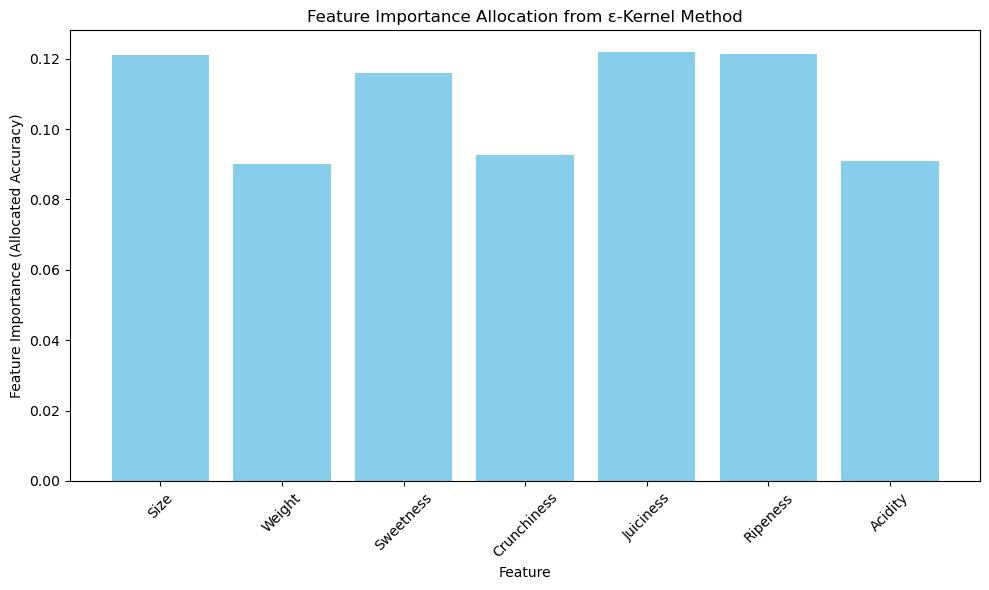

In [ ]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split


def all_coalitions(n):
    features = list(range(n))
    coalitions = []
    for r in range(1, n+1):
        for subset in itertools.combinations(features, r):
            coalitions.append(frozenset(subset))
    return coalitions

def compute_value(coalition, X_train, X_test, y_train, y_test):
    if len(coalition) == 0:
        return 0.0
    cols = list(coalition)
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train[:, cols], y_train)
    y_pred = model.predict(X_test[:, cols])
    return accuracy_score(y_test, y_pred)

def compute_surplus(x, i, j, v_dict):
    best = -np.inf
    for coalition, value in v_dict.items():
        if i in coalition and j not in coalition:
            payoff_sum = sum(x[k] for k in coalition)
            surplus = value - payoff_sum
            if surplus > best:
                best = surplus
    return best

def epsilon_kernel(x_init, v_dict, epsilon, v_full, individual_values, n):
    x = np.array(x_init, dtype=float)
    max_iter = 10000
    for iteration in range(max_iter):
        delta = 0
        chosen_pair = None

        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                s_ij = compute_surplus(x, i, j, v_dict)
                s_ji = compute_surplus(x, j, i, v_dict)
                diff = s_ij - s_ji
                if diff > delta:
                    delta = diff
                    chosen_pair = (i, j)

        if delta <= epsilon * v_full:
            print(f"Converged after {iteration} iterations with delta = {delta:.4f}")
            break

        if chosen_pair is None:
            print("No eligible pair found; stopping.")
            break

        i_star, j_star = chosen_pair
        max_transfer = x[j_star] - individual_values[j_star]
        d = min(delta / 2, max_transfer)
        if d <= 0:
            print("No further transfer possible without violating individual rationality; stopping.")
            break

        x[i_star] += d
        x[j_star] -= d

    return x, iteration, delta


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})


target_column = "Quality"
feature_columns = [col for col in df.columns if col != target_column]
X_full = df[feature_columns].values
y_full = df[target_column].values

X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=42)
n_features = X_train.shape[1]

# Precompute Value Function v(C) for Each Coalition Using Test Accuracy.

coalitions = all_coalitions(n_features)

v_dict = {}
for coalition in coalitions:
    v_val = compute_value(coalition, X_train, X_test, y_train, y_test)
    v_dict[coalition] = v_val

full_coalition = frozenset(range(n_features))
v_full = v_dict[full_coalition]

individual_values = []
for i in range(n_features):
    indiv = frozenset([i])
    individual_values.append(v_dict[indiv])

print("v(full):", v_full)
print("Individual values:", individual_values)


from collections import defaultdict

def approximate_banzhaf_init(v_dict, n_features, v_full):
    banzhaf_raw = defaultdict(float)

    for coalition in v_dict:
        for i in range(n_features):
            if i not in coalition:
                with_i = coalition.union({i})
                if with_i in v_dict:
                    marginal = v_dict[with_i] - v_dict[coalition]
                    banzhaf_raw[i] += marginal

    # Convert to list and clip negatives
    scores = [max(banzhaf_raw[i], 1e-4) for i in range(n_features)]

    # Normalize to sum to v_full
    total = sum(scores)
    return [v_full * (score / total) for score in scores]


epsilon = 0.01
x_final, iterations, final_delta = epsilon_kernel(x_init, v_dict, epsilon, v_full, individual_values, n_features)

print("\nFinal feature importance allocation:", x_final)
print("Number of iterations:", iterations)
print("Final delta:", final_delta)


plt.figure(figsize=(10, 6))
plt.bar(feature_columns, x_final, color='skyblue')
plt.xlabel('Feature')
plt.ylabel('Feature Importance (Allocated Accuracy)')
plt.title('Feature Importance Allocation from ε-Kernel Method')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Total PRIME (weighted entropy):
Shapley Method: 15.6886
Gately Method: 15.9515


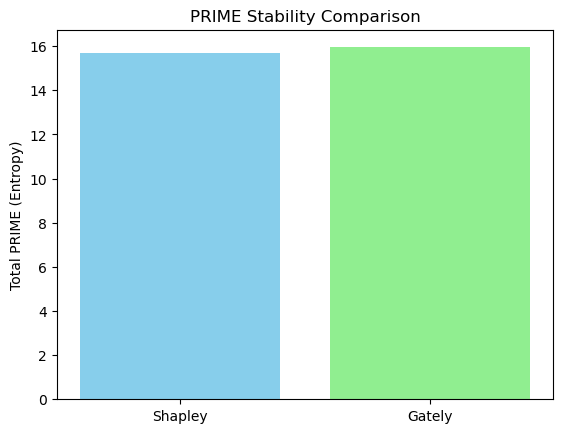

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import itertools
from scipy.stats import entropy
import matplotlib.pyplot as plt


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

X = df.drop('Quality', axis=1)
y = df['Quality']
features = X.columns.tolist()


# Compute accuracy given subset of features
def compute_accuracy(X_tr, y_tr, X_te, y_te, subset):
    if len(subset) == 0:
        return 0.0
    model = LogisticRegression(solver='liblinear')
    model.fit(X_tr[subset], y_tr)
    return accuracy_score(y_te, model.predict(X_te[subset]))

# Calculate Shapley values
def shapley_values(X_tr, y_tr, X_te, y_te, features):
    accuracy_values = {}
    for r in range(len(features) + 1):
        for subset in itertools.combinations(features, r):
            accuracy_values[frozenset(subset)] = compute_accuracy(X_tr, y_tr, X_te, y_te, list(subset))

    shapley_vals = {f: 0 for f in features}
    n = len(features)

    for f in features:
        shapley_sum = 0
        for r in range(n):
            for subset in itertools.combinations([feat for feat in features if feat != f], r):
                subset = frozenset(subset)
                with_f = accuracy_values[subset | {f}]
                without_f = accuracy_values[subset]
                marginal_contrib = with_f - without_f
                weight = (np.math.factorial(len(subset)) * np.math.factorial(n - len(subset) - 1)) / np.math.factorial(n)
                shapley_sum += weight * marginal_contrib
        shapley_vals[f] = shapley_sum
    return shapley_vals

# Calculate Gately values
def gately_values(X_tr, y_tr, X_te, y_te, features):
    vN = compute_accuracy(X_tr, y_tr, X_te, y_te, features)
    v_single = {f: compute_accuracy(X_tr, y_tr, X_te, y_te, [f]) for f in features}
    v_without = {f: compute_accuracy(X_tr, y_tr, X_te, y_te, [feat for feat in features if feat != f]) for f in features}

    numerator = (len(features) - 1) * vN - sum(v_without.values())
    denom = vN - sum(v_single.values())

    d_star = numerator / denom if denom != 0 else 0

    gately_vals = {}
    for f in features:
        M_i = vN - v_without[f]
        gately_vals[f] = (M_i + d_star * v_single[f]) / (d_star + 1) if (d_star + 1) != 0 else 0
    return gately_vals

num_permutations = 10
shapley_rankings = []
gately_rankings = []

for i in range(num_permutations):
    # Permute labels to create different data "scenarios"
    y_permuted = y.sample(frac=1, random_state=i).reset_index(drop=True)

    X_train, X_test, y_train, y_test = train_test_split(X, y_permuted, test_size=0.2, random_state=i)

    # Recompute Shapley and Gately for each permutation
    shap_vals = shapley_values(X_train, y_train, X_test, y_test, features)
    gat_vals = gately_values(X_train, y_train, X_test, y_test, features)

    # Store rankings based on computed values
    shap_rank = sorted(shap_vals, key=shap_vals.get, reverse=True)
    gately_rank = sorted(gat_vals, key=gat_vals.get, reverse=True)

    shapley_rankings.append(shap_rank)
    gately_rankings.append(gately_rank)

def compute_prime(rankings, features):
    rank_counts = {feat: np.zeros(len(features)) for feat in features}

    for rank_list in rankings:
        for rank, feat in enumerate(rank_list):
            rank_counts[feat][rank] += 1

    rank_probs = {feat: counts / len(rankings) for feat, counts in rank_counts.items()}

    feature_entropies = {feat: entropy(probs, base=2) for feat, probs in rank_probs.items()}
    total_entropy = sum(feature_entropies.values())
    return feature_entropies, total_entropy

shapley_feature_entropy, shapley_total_entropy = compute_prime(shapley_rankings, features)
gately_feature_entropy, gately_total_entropy = compute_prime(gately_rankings, features)


print("Total PRIME (weighted entropy):")
print(f"Shapley Method: {shapley_total_entropy:.4f}")
print(f"Gately Method: {gately_total_entropy:.4f}")

methods = ['Shapley', 'Gately']
entropies = [shapley_total_entropy, gately_total_entropy]

plt.bar(methods, entropies, color=['skyblue', 'lightgreen'])
plt.ylabel("Total PRIME (Entropy)")
plt.title("PRIME Stability Comparison")
plt.show()

Shapley PRIME (Weighted Entropy): -0.0000
Gately PRIME (Weighted Entropy): -0.0000

Shapley PRIME per Feature:
Size: -0.0000
Weight: -0.0000
Sweetness: -0.0000
Crunchiness: -0.0000
Juiciness: -0.0000
Ripeness: -0.0000
Acidity: -0.0000

Gately PRIME per Feature:
Size: -0.0000
Weight: -0.0000
Sweetness: -0.0000
Crunchiness: -0.0000
Juiciness: -0.0000
Ripeness: -0.0000
Acidity: -0.0000


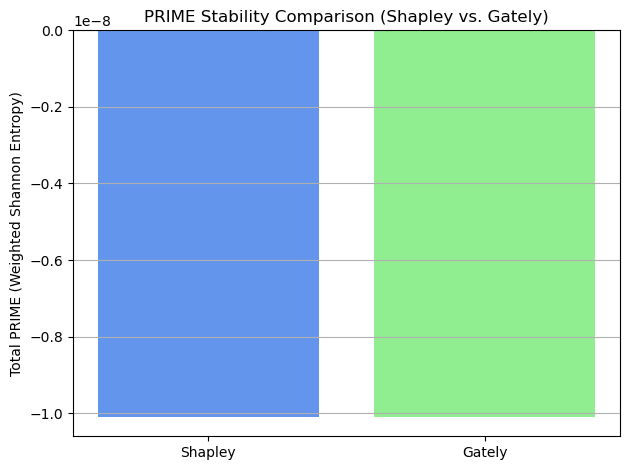

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import itertools
import matplotlib.pyplot as plt

# Step 1: Load and preprocess dataset
df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")
if 'A_id' in df.columns:
    df.drop('A_id', axis=1, inplace=True)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

X = df.drop(columns=["Quality"])
y = df["Quality"]
features = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Accuracy function defined
def compute_accuracy(subset):
    if len(subset) == 0:
        return 0.0
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train[subset], y_train)
    y_pred = model.predict(X_test[subset])
    return accuracy_score(y_test, y_pred)

# Step 2: Explicit Shapley and Gately calculations
def shapley_values(features):
    accuracy_values = {}
    for r in range(len(features)+1):
        for subset in itertools.combinations(features, r):
            accuracy_values[frozenset(subset)] = compute_accuracy(list(subset))

    shapley = {f: 0 for f in features}
    n = len(features)
    for f in features:
        shap_sum = 0
        for r in range(n):
            for subset in itertools.combinations([feat for feat in features if feat != f], r):
                subset = frozenset(subset)
                marginal_contrib = accuracy_values[subset | {f}] - accuracy_values[subset]
                weight = np.math.factorial(len(subset)) * np.math.factorial(n - len(subset) - 1) / np.math.factorial(n)
                shap_sum += weight * marginal_contrib
        shapley[f] = shap_sum
    return shapley

def gately_values(features):
    vN = compute_accuracy(features)
    v_single = {f: compute_accuracy([f]) for f in features}
    v_without = {f: compute_accuracy([feat for feat in features if feat != f]) for f in features}
    numerator = (len(features)-1)*vN - sum(v_without.values())
    denominator = vN - sum(v_single.values())
    d_star = numerator / denominator if denominator != 0 else 0
    gately = {}
    for f in features:
        M_i = vN - v_without[f]
        gately[f] = (M_i + d_star * v_single[f]) / (d_star + 1) if (d_star + 1) != 0 else 0
    return gately

# Step 3: Explicit permutations for PRIME evaluation
num_permutations = 30
shapley_rankings, gately_rankings = [], []

for perm in range(num_permutations):
    X_test_perm = X_test.copy()
    for feature in features:
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

    # Explicit recalculation
    shap_vals = shapley_values(features)
    gat_vals = gately_values(features)

    shapley_rankings.append(sorted(shap_vals, key=shap_vals.get, reverse=True))
    gately_rankings.append(sorted(gat_vals, key=gat_vals.get, reverse=True))

# Step 4: Explicit PRIME (Algorithm 12) implementation
def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    prime_entropy = {}
    for feat in features:
        freq = rank_counts[feat]
        prob = np.ones_like(freq) / len(features)
        weighted_prob = prob * freq
        total_weighted = np.sum(weighted_prob)
        normalized_wp = weighted_prob / total_weighted
        H = -normalized_wp * np.log2(normalized_wp + 1e-9)
        prime_entropy[feat] = np.sum(H)

    total_entropy = sum(prime_entropy.values())
    return prime_entropy, total_entropy

shapley_prime_entropy, shapley_total_prime = explicit_prime(shapley_rankings, features)
gately_prime_entropy, gately_total_prime = explicit_prime(gately_rankings, features)

# Step 5: Clear PRIME Results
print(f"Shapley PRIME (Weighted Entropy): {shapley_total_prime:.4f}")
print(f"Gately PRIME (Weighted Entropy): {gately_total_prime:.4f}")

# Detailed entropy per feature printed
print("\nShapley PRIME per Feature:")
for f in features:
    print(f"{f}: {shapley_prime_entropy[f]:.4f}")

print("\nGately PRIME per Feature:")
for f in features:
    print(f"{f}: {gately_prime_entropy[f]:.4f}")

# Step 6: Visualization
methods = ['Shapley', 'Gately']
entropies = [shapley_total_prime, gately_total_prime]

plt.bar(methods, entropies, color=['cornflowerblue', 'lightgreen'])
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('PRIME Stability Comparison (Shapley vs. Gately)')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


---- Shapley Method PRIME Debugging ----

Debug (Size): Frequency counts per rank: [30.  0.  0.  0.  0.  0.  0.]
Debug (Size): Weighted probabilities before normalization: [4.28571429 0.         0.         0.         0.         0.
 0.        ]
Debug (Size): Total weighted sum: 4.285714285714286
Debug (Size): Normalized weighted probabilities: [1. 0. 0. 0. 0. 0. 0.]
Debug (Size): Entropy: -0.000000

Debug (Weight): Frequency counts per rank: [ 0.  0.  0.  0. 30.  0.  0.]
Debug (Weight): Weighted probabilities before normalization: [0.         0.         0.         0.         4.28571429 0.
 0.        ]
Debug (Weight): Total weighted sum: 4.285714285714286
Debug (Weight): Normalized weighted probabilities: [0. 0. 0. 0. 1. 0. 0.]
Debug (Weight): Entropy: -0.000000

Debug (Sweetness): Frequency counts per rank: [ 0.  0. 30.  0.  0.  0.  0.]
Debug (Sweetness): Weighted probabilities before normalization: [0.         0.         4.28571429 0.         0.         0.
 0.        ]
Debug (Sweetnes

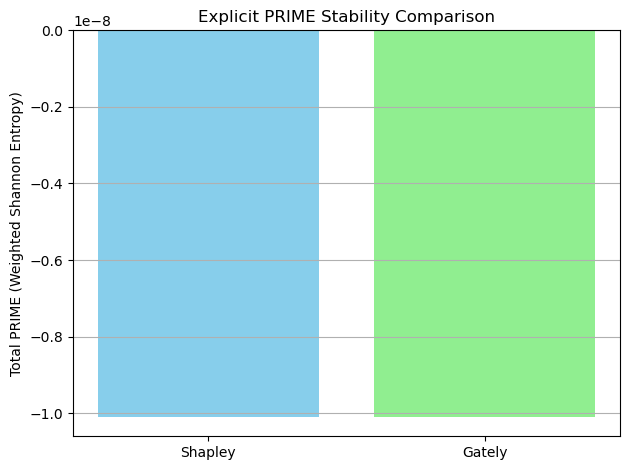

In [18]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import itertools
import matplotlib.pyplot as plt

# Load and preprocess dataset
df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")
if 'A_id' in df.columns:
    df.drop('A_id', axis=1, inplace=True)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

X = df.drop(columns=["Quality"])
y = df["Quality"]
features = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Accuracy function
def compute_accuracy(subset):
    if len(subset) == 0:
        return 0.0
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train[subset], y_train)
    y_pred = model.predict(X_test[subset])
    return accuracy_score(y_test, y_pred)

# Shapley calculation
def shapley_values(features):
    accuracy_values = {}
    for r in range(len(features)+1):
        for subset in itertools.combinations(features, r):
            accuracy_values[frozenset(subset)] = compute_accuracy(list(subset))

    shapley = {f: 0 for f in features}
    n = len(features)
    for f in features:
        shap_sum = 0
        for r in range(n):
            for subset in itertools.combinations([feat for feat in features if feat != f], r):
                subset = frozenset(subset)
                marginal_contrib = accuracy_values[subset | {f}] - accuracy_values[subset]
                weight = np.math.factorial(len(subset)) * np.math.factorial(n - len(subset) - 1) / np.math.factorial(n)
                shap_sum += weight * marginal_contrib
        shapley[f] = shap_sum
    return shapley

# Gately calculation
def gately_values(features):
    vN = compute_accuracy(features)
    v_single = {f: compute_accuracy([f]) for f in features}
    v_without = {f: compute_accuracy([feat for feat in features if feat != f]) for f in features}
    numerator = (len(features)-1)*vN - sum(v_without.values())
    denominator = vN - sum(v_single.values())
    d_star = numerator / denominator if denominator != 0 else 0
    gately = {}
    for f in features:
        M_i = vN - v_without[f]
        gately[f] = (M_i + d_star * v_single[f]) / (d_star + 1) if (d_star + 1) != 0 else 0
    return gately

# Perform explicit permutations for PRIME evaluation
num_permutations = 30
shapley_rankings, gately_rankings = [], []

for perm in range(num_permutations):
    X_test_perm = X_test.copy()
    for feature in features:
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

    shap_vals = shapley_values(features)
    gat_vals = gately_values(features)

    shapley_rankings.append(sorted(shap_vals, key=shap_vals.get, reverse=True))
    gately_rankings.append(sorted(gat_vals, key=gat_vals.get, reverse=True))

# PRIME calculation (Algorithm 12 with debug statements)
def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    # Counting rankings
    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    total_entropy = 0.0
    for feat in features:
        freq = rank_counts[feat]
        print(f"\nDebug ({feat}): Frequency counts per rank: {freq}")

        prob = np.ones_like(freq) / len(features)
        weighted_prob = prob * freq
        print(f"Debug ({feat}): Weighted probabilities before normalization: {weighted_prob}")

        total_weighted = np.sum(weighted_prob)
        print(f"Debug ({feat}): Total weighted sum: {total_weighted}")

        if total_weighted == 0:
            print(f"Warning ({feat}): total_weighted is zero, skipping entropy calculation.")
            continue

        normalized_wp = weighted_prob / total_weighted
        print(f"Debug ({feat}): Normalized weighted probabilities: {normalized_wp}")

        H = -normalized_wp * np.log2(normalized_wp + 1e-9)
        entropy_feat = np.sum(H)
        print(f"Debug ({feat}): Entropy: {entropy_feat:.6f}")

        total_entropy += entropy_feat

    print(f"\nDebug: Total entropy summed across all features: {total_entropy:.6f}")
    return total_entropy

# Calculate PRIME for each method with detailed debugging
print("\n---- Shapley Method PRIME Debugging ----")
shapley_total_prime = explicit_prime(shapley_rankings, features)

print("\n---- Gately Method PRIME Debugging ----")
gately_total_prime = explicit_prime(gately_rankings, features)

# Results outputted
print("\n\nFinal PRIME Results explicitly:")
print(f"Shapley PRIME (Weighted Entropy): {shapley_total_prime:.6f}")
print(f"Gately PRIME (Weighted Entropy): {gately_total_prime:.6f}")

# Plot for comparison
methods = ['Shapley', 'Gately']
entropies = [shapley_total_prime, gately_total_prime]

plt.bar(methods, entropies, color=['skyblue', 'lightgreen'])
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('Explicit PRIME Stability Comparison')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

Dataset loaded with features: ['Size', 'Weight', 'Sweetness', 'Crunchiness', 'Juiciness', 'Ripeness', 'Acidity']
Data split into train/test: (3200, 7), (800, 7)

[Step 5] Starting permutations for PRIME calculation...

Permutation 1/20


Debug permutation 1 feature 'Size': Shapley ranks ['Juiciness', 'Ripeness', 'Sweetness', 'Crunchiness', 'Weight', 'Acidity', 'Size'], Gately ranks ['Juiciness', 'Ripeness', 'Crunchiness', 'Sweetness', 'Weight', 'Acidity', 'Size']


Debug permutation 1 feature 'Weight': Shapley ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Crunchiness', 'Weight', 'Acidity'], Gately ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Crunchiness', 'Weight', 'Acidity']


Debug permutation 1 feature 'Sweetness': Shapley ranks ['Juiciness', 'Ripeness', 'Size', 'Crunchiness', 'Acidity', 'Weight', 'Sweetness'], Gately ranks ['Juiciness', 'Ripeness', 'Size', 'Acidity', 'Crunchiness', 'Weight', 'Sweetness']


Debug permutation 1 feature 'Crunchiness': Shapley ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Crunchiness', 'Weight', 'Acidity'], Gately ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity']


Debug permutation 1 feature 'Juiciness': Shapley ranks ['Size', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity', 'Juiciness'], Gately ranks ['Size', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity', 'Juiciness']


... (130 outputs left out)

Debug permutation 20 feature 'Sweetness': Shapley ranks ['Juiciness', 'Size', 'Ripeness', 'Crunchiness', 'Acidity', 'Weight', 'Sweetness'], Gately ranks ['Juiciness', 'Size', 'Ripeness', 'Acidity', 'Crunchiness', 'Weight', 'Sweetness']


Debug permutation 20 feature 'Crunchiness': Shapley ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity'], Gately ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity']


Debug permutation 20 feature 'Juiciness': Shapley ranks ['Size', 'Sweetness', 'Ripeness', 'Crunchiness', 'Weight', 'Acidity', 'Juiciness'], Gately ranks ['Size', 'Sweetness', 'Ripeness', 'Acidity', 'Crunchiness', 'Weight', 'Juiciness']


Debug permutation 20 feature 'Ripeness': Shapley ranks ['Size', 'Sweetness', 'Juiciness', 'Weight', 'Crunchiness', 'Acidity', 'Ripeness'], Gately ranks ['Size', 'Sweetness', 'Juiciness', 'Weight', 'Ripeness', 'Crunchiness', 'Acidity']
Debug permutation 20 feature 'Acidity': Shapley ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity'], Gately ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Crunchiness', 'Weight', 'Acidity']

[Step 6] Calculating PRIME explicitly for Shapley...

Debug PRIME feature 'Size':
 Frequency counts: [100.  10.  10.   1.   0.   2.  17.]
 Weighted probs: [14.28571429  1.42857143  1.42857143  0.14285714  0.          0.28571429
  2.42857143]
 Normalized probs: [0.71428571 0.07142857 0.07142857 0.00714286 0.         0.01428571
 0.12142857]
 Entropy: 1.398490

Debug PRIME feature 'Weight':
 Frequency counts: [ 0.  0.  0. 32. 61. 44.  3.]
 Weighted probs: [0.         0.         0.         4.57142857 8.71428571 6.28571429
 0.428

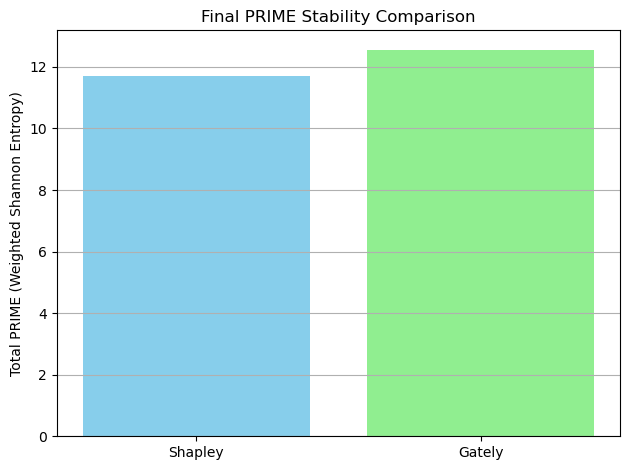

In [19]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import itertools
import matplotlib.pyplot as plt


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

if 'A_id' in df.columns:
    df.drop('A_id', axis=1, inplace=True)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

X = df.drop(columns=["Quality"])
y = df["Quality"]
features = X.columns.tolist()
print(f"Dataset loaded with features: {features}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Data split into train/test: {X_train.shape}, {X_test.shape}")

def compute_accuracy(X_tr, y_tr, X_te, y_te, subset):
    if len(subset) == 0:
        return 0.0
    model = LogisticRegression(solver='liblinear')
    model.fit(X_tr[subset], y_tr)
    preds = model.predict(X_te[subset])
    return accuracy_score(y_te, preds)

def shapley_values(X_tr, y_tr, X_te, y_te, features):
    accuracy_values = {}
    for r in range(len(features)+1):
        for subset in itertools.combinations(features, r):
            accuracy_values[frozenset(subset)] = compute_accuracy(X_tr, y_tr, X_te, y_te, list(subset))

    shapley = {f: 0 for f in features}
    n = len(features)
    for f in features:
        shap_sum = 0
        for r in range(n):
            for subset in itertools.combinations([feat for feat in features if feat != f], r):
                subset = frozenset(subset)
                marginal_contrib = accuracy_values[subset | {f}] - accuracy_values[subset]
                weight = np.math.factorial(len(subset)) * np.math.factorial(n - len(subset) - 1) / np.math.factorial(n)
                shap_sum += weight * marginal_contrib
        shapley[f] = shap_sum
    return shapley

def gately_values(X_tr, y_tr, X_te, y_te, features):
    vN = compute_accuracy(X_tr, y_tr, X_te, y_te, features)
    v_single = {f: compute_accuracy(X_tr, y_tr, X_te, y_te, [f]) for f in features}
    v_without = {f: compute_accuracy(X_tr, y_tr, X_te, y_te, [feat for feat in features if feat != f]) for f in features}
    numerator = (len(features)-1)*vN - sum(v_without.values())
    denominator = vN - sum(v_single.values())
    d_star = numerator / denominator if denominator != 0 else 0
    gately = {}
    for f in features:
        M_i = vN - v_without[f]
        gately[f] = (M_i + d_star * v_single[f]) / (d_star + 1) if (d_star + 1) != 0 else 0
    return gately

num_permutations = 20
shapley_rankings, gately_rankings = [], []

print("\n[Step 5] Starting permutations for PRIME calculation...")
for perm in range(num_permutations):
    print(f"\nPermutation {perm+1}/{num_permutations}")
    for feature in features:
        X_test_perm = X_test.copy()
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

        # Recalculate importance
        shap_vals = shapley_values(X_train, y_train, X_test_perm, y_test, features)
        gat_vals = gately_values(X_train, y_train, X_test_perm, y_test, features)

        # Rank and store
        shapley_ranking = sorted(shap_vals, key=shap_vals.get, reverse=True)
        gately_ranking = sorted(gat_vals, key=gat_vals.get, reverse=True)

        shapley_rankings.append(shapley_ranking)
        gately_rankings.append(gately_ranking)

        print(f"Debug permutation {perm+1} feature '{feature}': Shapley ranks {shapley_ranking}, Gately ranks {gately_ranking}")

def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    total_entropy = 0.0
    for feat in features:
        freq = rank_counts[feat]
        prob = np.ones_like(freq) / len(features)
        wp = prob * freq
        total_wp = np.sum(wp)

        if total_wp == 0:
            continue

        normalized_wp = wp / total_wp
        entropy_feat = -np.sum(normalized_wp * np.log2(normalized_wp + 1e-9))
        total_entropy += entropy_feat

        print(f"\nDebug PRIME feature '{feat}':")
        print(f"Frequency counts: {freq}")
        print(f"Weighted probs: {wp}")
        print(f"Normalized probs: {normalized_wp}")
        print(f"Entropy: {entropy_feat:.6f}")

    return total_entropy

print("\n[Step 6] Calculating PRIME explicitly for Shapley...")
shapley_total_prime = explicit_prime(shapley_rankings, features)

print("\n[Step 6] Calculating PRIME explicitly for Gately...")
gately_total_prime = explicit_prime(gately_rankings, features)

print("\n[Step 7] PRIME Final Results:")
print(f"Shapley PRIME: {shapley_total_prime:.6f}")
print(f"Gately PRIME: {gately_total_prime:.6f}")

# Visualization
plt.bar(['Shapley', 'Gately'], [shapley_total_prime, gately_total_prime], color=['skyblue', 'lightgreen'])
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('Final PRIME Stability Comparison')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

Dataset loaded with features: ['Size', 'Weight', 'Sweetness', 'Crunchiness', 'Juiciness', 'Ripeness', 'Acidity']
Data split into train/test: (3200, 7), (800, 7)

[Step 5] Starting permutations for PRIME calculation...

Permutation 1/35


Debug permutation 1 feature 'Size': Shapley ranks ['Juiciness', 'Ripeness', 'Sweetness', 'Size', 'Crunchiness', 'Weight', 'Acidity'], Gately ranks ['Juiciness', 'Sweetness', 'Ripeness', 'Acidity', 'Crunchiness', 'Size', 'Weight']


Debug permutation 1 feature 'Weight': Shapley ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Crunchiness', 'Weight', 'Acidity'], Gately ranks ['Size', 'Juiciness', 'Ripeness', 'Sweetness', 'Acidity', 'Crunchiness', 'Weight']


Debug permutation 1 feature 'Sweetness': Shapley ranks ['Juiciness', 'Ripeness', 'Size', 'Acidity', 'Crunchiness', 'Weight', 'Sweetness'], Gately ranks ['Juiciness', 'Ripeness', 'Size', 'Acidity', 'Crunchiness', 'Weight', 'Sweetness']


Debug permutation 1 feature 'Crunchiness': Shapley ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Crunchiness', 'Weight', 'Acidity'], Gately ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity']


Debug permutation 1 feature 'Juiciness': Shapley ranks ['Size', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity', 'Juiciness'], Gately ranks ['Size', 'Sweetness', 'Ripeness', 'Crunchiness', 'Weight', 'Acidity', 'Juiciness']


... (235 outputs left out)

Debug permutation 35 feature 'Sweetness': Shapley ranks ['Juiciness', 'Size', 'Ripeness', 'Acidity', 'Crunchiness', 'Weight', 'Sweetness'], Gately ranks ['Juiciness', 'Size', 'Ripeness', 'Acidity', 'Weight', 'Crunchiness', 'Sweetness']


Debug permutation 35 feature 'Crunchiness': Shapley ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity'], Gately ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity']


Debug permutation 35 feature 'Juiciness': Shapley ranks ['Size', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity', 'Juiciness'], Gately ranks ['Size', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity', 'Juiciness']


Debug permutation 35 feature 'Ripeness': Shapley ranks ['Size', 'Sweetness', 'Juiciness', 'Weight', 'Crunchiness', 'Acidity', 'Ripeness'], Gately ranks ['Size', 'Sweetness', 'Juiciness', 'Weight', 'Crunchiness', 'Acidity', 'Ripeness']
Debug permutation 35 feature 'Acidity': Shapley ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Acidity', 'Crunchiness', 'Weight'], Gately ranks ['Size', 'Juiciness', 'Sweetness', 'Ripeness', 'Weight', 'Crunchiness', 'Acidity']

[Step 6] Calculating PRIME explicitly for Shapley...

Debug PRIME feature 'Size':
 Frequency counts: [175.  14.  21.   1.   0.   5.  29.]
 Weighted probs: [25.          2.          3.          0.14285714  0.          0.71428571
  4.14285714]
 Normalized probs: [0.71428571 0.05714286 0.08571429 0.00408163 0.         0.02040816
 0.11836735]
 Entropy: 1.397884

Debug PRIME feature 'Weight':
 Frequency counts: [ 0.  0.  0. 62. 96. 82.  5.]
 Weighted probs: [ 0.          0.          0.          8.85714286 13.71428571 11.71428571


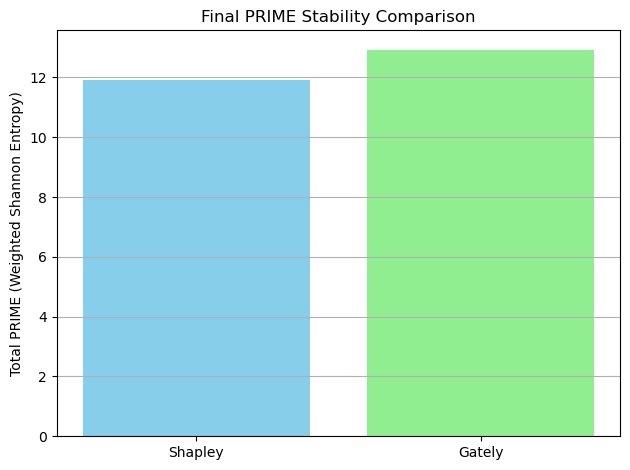

In [20]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import itertools
import matplotlib.pyplot as plt


df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

if 'A_id' in df.columns:
    df.drop('A_id', axis=1, inplace=True)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

X = df.drop(columns=["Quality"])
y = df["Quality"]
features = X.columns.tolist()
print(f"Dataset loaded with features: {features}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Data split into train/test: {X_train.shape}, {X_test.shape}")

def compute_accuracy(X_tr, y_tr, X_te, y_te, subset):
    if len(subset) == 0:
        return 0.0
    model = LogisticRegression(solver='liblinear')
    model.fit(X_tr[subset], y_tr)
    preds = model.predict(X_te[subset])
    return accuracy_score(y_te, preds)

def shapley_values(X_tr, y_tr, X_te, y_te, features):
    accuracy_values = {}
    for r in range(len(features)+1):
        for subset in itertools.combinations(features, r):
            accuracy_values[frozenset(subset)] = compute_accuracy(X_tr, y_tr, X_te, y_te, list(subset))

    shapley = {f: 0 for f in features}
    n = len(features)
    for f in features:
        shap_sum = 0
        for r in range(n):
            for subset in itertools.combinations([feat for feat in features if feat != f], r):
                subset = frozenset(subset)
                marginal_contrib = accuracy_values[subset | {f}] - accuracy_values[subset]
                weight = np.math.factorial(len(subset)) * np.math.factorial(n - len(subset) - 1) / np.math.factorial(n)
                shap_sum += weight * marginal_contrib
        shapley[f] = shap_sum
    return shapley

def gately_values(X_tr, y_tr, X_te, y_te, features):
    vN = compute_accuracy(X_tr, y_tr, X_te, y_te, features)
    v_single = {f: compute_accuracy(X_tr, y_tr, X_te, y_te, [f]) for f in features}
    v_without = {f: compute_accuracy(X_tr, y_tr, X_te, y_te, [feat for feat in features if feat != f]) for f in features}
    numerator = (len(features)-1)*vN - sum(v_without.values())
    denominator = vN - sum(v_single.values())
    d_star = numerator / denominator if denominator != 0 else 0
    gately = {}
    for f in features:
        M_i = vN - v_without[f]
        gately[f] = (M_i + d_star * v_single[f]) / (d_star + 1) if (d_star + 1) != 0 else 0
    return gately

num_permutations = 35
shapley_rankings, gately_rankings = [], []

print("\n[Step 5] Starting permutations for PRIME calculation...")
for perm in range(num_permutations):
    print(f"\nPermutation {perm+1}/{num_permutations}")
    for feature in features:
        X_test_perm = X_test.copy()
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

        # Recalculate importance
        shap_vals = shapley_values(X_train, y_train, X_test_perm, y_test, features)
        gat_vals = gately_values(X_train, y_train, X_test_perm, y_test, features)

        # Rank and store
        shapley_ranking = sorted(shap_vals, key=shap_vals.get, reverse=True)
        gately_ranking = sorted(gat_vals, key=gat_vals.get, reverse=True)

        shapley_rankings.append(shapley_ranking)
        gately_rankings.append(gately_ranking)

        print(f"Debug permutation {perm+1} feature '{feature}': Shapley ranks {shapley_ranking}, Gately ranks {gately_ranking}")

def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    total_entropy = 0.0
    for feat in features:
        freq = rank_counts[feat]
        prob = np.ones_like(freq) / len(features)
        wp = prob * freq
        total_wp = np.sum(wp)

        if total_wp == 0:
            continue

        normalized_wp = wp / total_wp
        entropy_feat = -np.sum(normalized_wp * np.log2(normalized_wp + 1e-9))
        total_entropy += entropy_feat

        print(f"\nDebug PRIME feature '{feat}':")
        print(f"Frequency counts: {freq}")
        print(f"Weighted probs: {wp}")
        print(f"Normalized probs: {normalized_wp}")
        print(f"Entropy: {entropy_feat:.6f}")

    return total_entropy

print("\n[Step 6] Calculating PRIME explicitly for Shapley...")
shapley_total_prime = explicit_prime(shapley_rankings, features)

print("\n[Step 6] Calculating PRIME explicitly for Gately...")
gately_total_prime = explicit_prime(gately_rankings, features)

print("\n[Step 7] PRIME Final Results:")
print(f"Shapley PRIME: {shapley_total_prime:.6f}")
print(f"Gately PRIME: {gately_total_prime:.6f}")

# Visualization
plt.bar(['Shapley', 'Gately'], [shapley_total_prime, gately_total_prime], color=['skyblue', 'lightgreen'])
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('Final PRIME Stability Comparison')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


[PRIME - Nucleolus] Starting permutations for stability calculation...
Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

[Final Results] PRIME Stability (Nucleolus):
Nucleolus PRIME: 14.982522


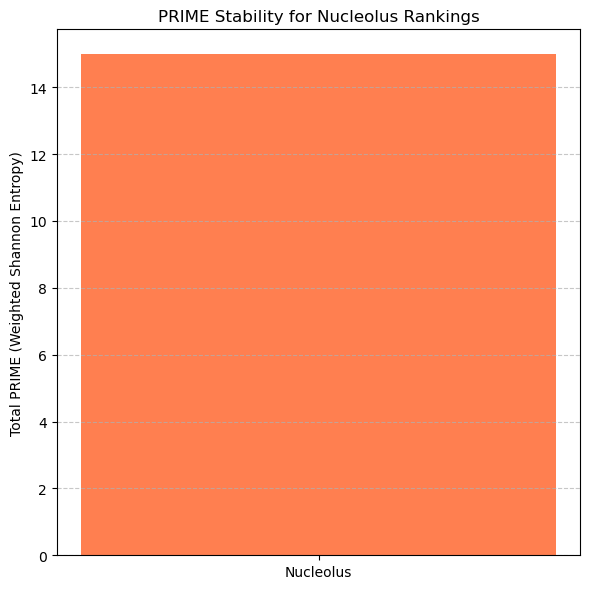

In [21]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

num_permutations = 20
nucleolus_rankings = []

print("\n[PRIME - Nucleolus] Starting permutations for stability calculation...")

for perm in range(num_permutations):
    print(f"Permutation {perm+1}/{num_permutations}")
    X_test_perm = X_test.copy()

    # Permute each feature individually
    for feature in features:
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

        # Recalculate accuracies after permutation
        accuracy_values_perm = {}
        for r in range(len(features)+1):
            for subset in itertools.combinations(features, r):
                subset = frozenset(subset)
                accuracy_values_perm[subset] = compute_accuracy(X_train, y_train, X_test_perm, y_test, list(subset))

        # Compute nucleolus for permuted accuracies
        total_value_perm = sum(accuracy_values_perm[frozenset({f})] for f in features)
        full_value_perm = accuracy_values_perm[frozenset(features)]
        initial_x_perm = {feature: (accuracy_values_perm[frozenset({feature})] / total_value_perm) * full_value_perm
                          for feature in features}

        def compute_excess(S, x_values, accuracy_dict):
            subset_excess = []
            for r in range(1, len(S) + 1):
                for T in itertools.combinations(S, r):
                    T = frozenset(T)
                    if T in accuracy_dict and T:
                        excess = accuracy_dict[T] - sum(x_values.get(f, 0) for f in T)
                        subset_excess.append(excess)
            return max(subset_excess) if subset_excess else 0

        excess_values_perm = {S: compute_excess(S, initial_x_perm, accuracy_values_perm) for S in accuracy_values_perm if S}

        # Iterative nucleolus adjustments
        x_perm = initial_x_perm.copy()
        iteration = 0
        max_iterations = 500

        while iteration < max_iterations:
            max_excess = max(excess_values_perm.values())
            coalitions_with_max_excess = [S for S, excess in excess_values_perm.items() if excess == max_excess]
            if max_excess <= 1e-6:
                break

            adjustment = max_excess / len(features)
            for S in coalitions_with_max_excess:
                for feat in S:
                    x_perm[feat] += adjustment / len(S)

            # Recalculate excess after adjustments
            excess_values_perm = {S: compute_excess(S, x_perm, accuracy_values_perm) for S in accuracy_values_perm if S}
            iteration += 1

        nucleolus_ranking = sorted(x_perm, key=x_perm.get, reverse=True)
        nucleolus_rankings.append(nucleolus_ranking)

# Explicit PRIME calculation for Nucleolus rankings
def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    total_entropy = 0.0
    for feat in features:
        freq = rank_counts[feat]
        prob = np.ones_like(freq) / len(features)
        wp = prob * freq
        total_wp = np.sum(wp)

        if total_wp == 0:
            continue

        normalized_wp = wp / total_wp
        entropy_feat = -np.sum(normalized_wp * np.log2(normalized_wp + 1e-9))
        total_entropy += entropy_feat

    return total_entropy

nucleolus_total_prime = explicit_prime(nucleolus_rankings, features)

print("\n[Final Results] PRIME Stability (Nucleolus):")
print(f"Nucleolus PRIME: {nucleolus_total_prime:.6f}")

# Visualization
plt.figure(figsize=(6, 6))
plt.bar(['Nucleolus'], [nucleolus_total_prime], color='coral')
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('PRIME Stability for Nucleolus Rankings')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


[PRIME - CCRA] Starting permutations for stability calculation...
Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

[Final Results] PRIME Stability (CCRA):
CCRA PRIME: 15.101557


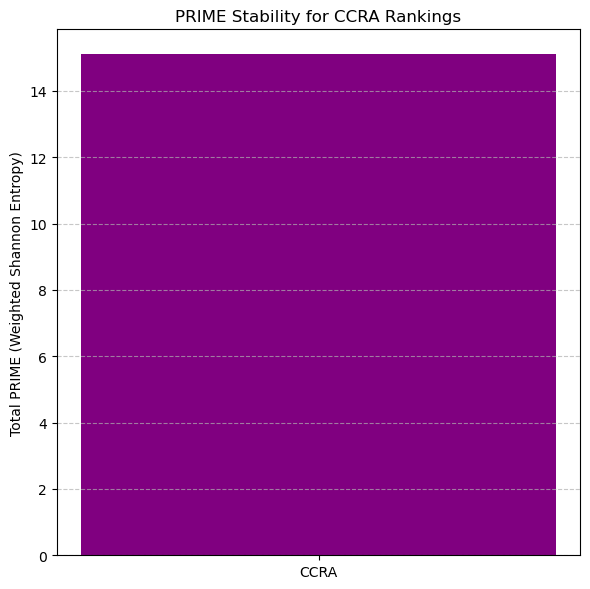

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import math

num_permutations = 20
ccra_rankings = []

print("\n[PRIME - CCRA] Starting permutations for stability calculation...")

# Define compute_ccra
def compute_ccra(claims, E):
    c_array = np.array(claims, dtype=float)
    n = len(c_array)
    V = np.zeros(n, dtype=float)
    all_indices = range(n)
    perm_count = math.factorial(n)

    for perm in itertools.permutations(all_indices):
        E_temp = E
        for idx in perm:
            award = min(c_array[idx], E_temp)
            V[idx] += award
            E_temp -= award
            if E_temp <= 0:
                break

    RA = V / perm_count
    return RA.tolist()

E = 0.7

for perm in range(num_permutations):
    print(f"Permutation {perm+1}/{num_permutations}")
    X_test_perm = X_test.copy()

    # Permute each feature individually
    for feature in features:
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

        # Recalculate claims after permutation
        claims_perm = []
        for single_feature in features:
            model = LogisticRegression(solver='liblinear')
            model.fit(X_train[[single_feature]], y_train)
            preds = model.predict(X_test_perm[[single_feature]])
            claim = accuracy_score(y_test, preds)
            claims_perm.append(claim)

        # Compute CCRA for permuted claims
        ccra_perm = compute_ccra(claims_perm, E)

        # Rank features according to CCRA allocations
        ccra_ranking = [feat for _, feat in sorted(zip(ccra_perm, features), reverse=True)]
        ccra_rankings.append(ccra_ranking)

# Explicit PRIME calculation for CCRA rankings
def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    total_entropy = 0.0
    for feat in features:
        freq = rank_counts[feat]
        prob = np.ones_like(freq) / len(features)
        wp = prob * freq
        total_wp = np.sum(wp)

        if total_wp == 0:
            continue

        normalized_wp = wp / total_wp
        entropy_feat = -np.sum(normalized_wp * np.log2(normalized_wp + 1e-9))
        total_entropy += entropy_feat

    return total_entropy

ccra_total_prime = explicit_prime(ccra_rankings, features)

print("\n[Final Results] PRIME Stability (CCRA):")
print(f"CCRA PRIME: {ccra_total_prime:.6f}")

# Visualization
plt.figure(figsize=(6, 6))
plt.bar(['CCRA'], [ccra_total_prime], color='purple')
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('PRIME Stability for CCRA Rankings')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


[PRIME - CEqL] Starting permutations for stability calculation...
Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

[Final Results] PRIME Stability (CEqL):
CEqL PRIME: 14.970877


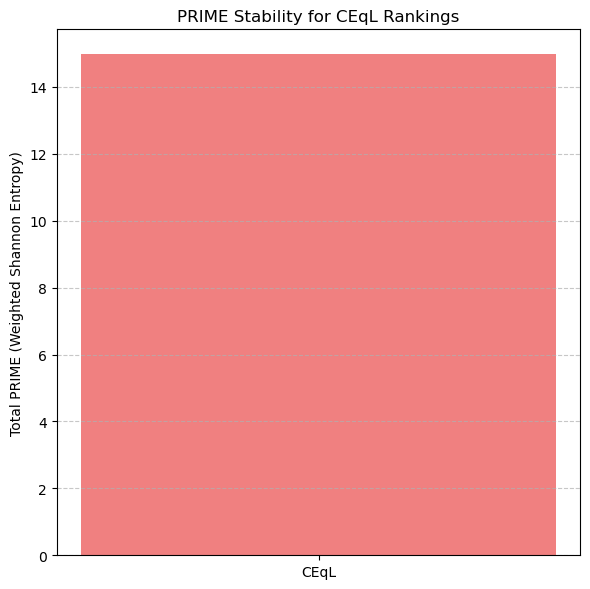

In [23]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import math

num_permutations = 20
ceql_rankings = []

print("\n[PRIME - CEqL] Starting permutations for stability calculation...")

# Define compute_ceql
def compute_ceql(claims, E):
    c_array = np.array(claims, dtype=float)
    total_claims = np.sum(c_array)

    if total_claims <= E:
        return c_array.tolist()

    lo, hi = 0.0, np.max(c_array)
    for _ in range(100):
        mid = (lo + hi) / 2.0
        current_sum = np.sum(np.maximum(0, c_array - mid))
        if current_sum > E:
            lo = mid
        else:
            hi = mid

    r = (lo + hi) / 2.0
    final_allocations = np.maximum(0, c_array - r)
    return final_allocations.tolist()

E = 0.7  # Endowment for CEqL calculation

for perm in range(num_permutations):
    print(f"Permutation {perm+1}/{num_permutations}")
    X_test_perm = X_test.copy()

    # Permute each feature individually
    for feature in features:
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

        # Recalculate claims after permutation
        claims_perm = []
        for single_feature in features:
            model = LogisticRegression(solver='liblinear')
            model.fit(X_train[[single_feature]], y_train)
            preds = model.predict(X_test_perm[[single_feature]])
            claim = accuracy_score(y_test, preds)
            claims_perm.append(claim)

        # Compute CEqL for permuted claims
        ceql_perm = compute_ceql(claims_perm, E)

        # Rank features according to CEqL allocations
        ceql_ranking = [feat for _, feat in sorted(zip(ceql_perm, features), reverse=True)]
        ceql_rankings.append(ceql_ranking)

# Explicit PRIME calculation for CEqL rankings
def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    total_entropy = 0.0
    for feat in features:
        freq = rank_counts[feat]
        prob = np.ones_like(freq) / len(features)
        wp = prob * freq
        total_wp = np.sum(wp)

        if total_wp == 0:
            continue

        normalized_wp = wp / total_wp
        entropy_feat = -np.sum(normalized_wp * np.log2(normalized_wp + 1e-9))
        total_entropy += entropy_feat

    return total_entropy

ceql_total_prime = explicit_prime(ceql_rankings, features)

print("\n[Final Results] PRIME Stability (CEqL):")
print(f"CEqL PRIME: {ceql_total_prime:.6f}")

# Visualization
plt.figure(figsize=(6, 6))
plt.bar(['CEqL'], [ceql_total_prime], color='lightcoral')
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('PRIME Stability for CEqL Rankings')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

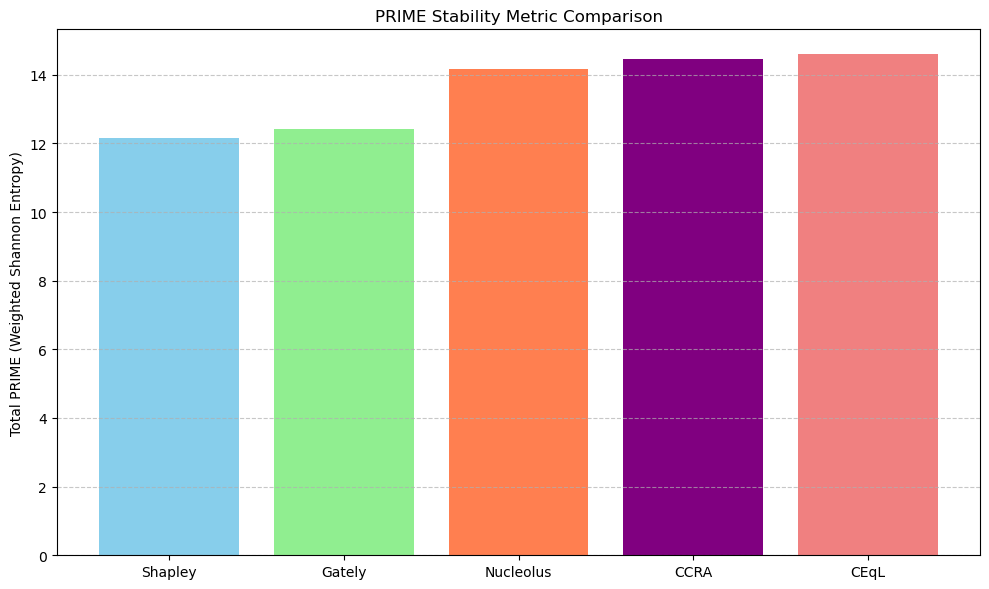

In [24]:
import matplotlib.pyplot as plt

# PRIME metric values
methods = ['Shapley', 'Gately', 'Nucleolus', 'CCRA', 'CEqL']
prime_values = [12.152556, 12.407751, 14.160309, 14.446727, 14.593607]

# Plotting all PRIME results together
plt.figure(figsize=(10, 6))
colors = ['skyblue', 'lightgreen', 'coral', 'purple', 'lightcoral']
plt.bar(methods, prime_values, color=colors)
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('PRIME Stability Metric Comparison')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Data split into train/test: (3200, 7), (800, 7)

[PRIME - Banzhaf] Starting permutations for stability calculation...
Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

[Final Results] PRIME Stability (Banzhaf):
Banzhaf PRIME: 14.344623


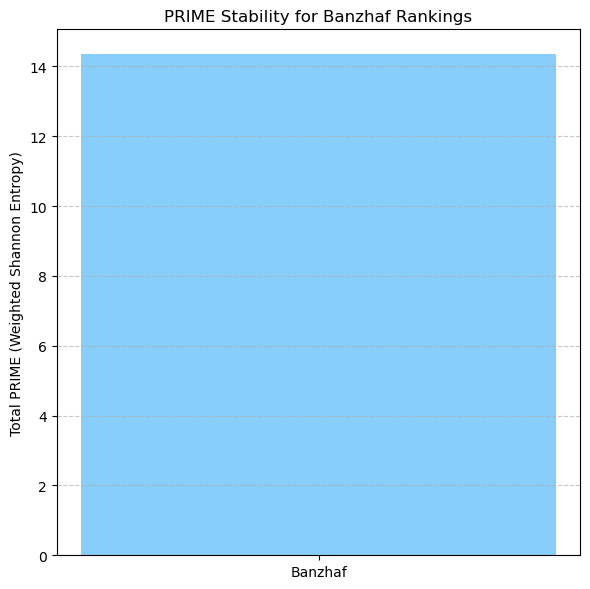

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import math

num_permutations = 20
banzhaf_rankings = []

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Data split into train/test: {X_train.shape}, {X_test.shape}")

def compute_accuracy(X_tr, y_tr, X_te, y_te, subset):
    if len(subset) == 0:
        return 0.0
    model = LogisticRegression(solver='liblinear')
    model.fit(X_tr[subset], y_tr)
    preds = model.predict(X_te[subset])
    return accuracy_score(y_te, preds)

print("\n[PRIME - Banzhaf] Starting permutations for stability calculation...")

for perm in range(num_permutations):
    print(f"Permutation {perm+1}/{num_permutations}")
    X_test_perm = X_test.copy()

    # Permute each feature individually
    for feature in features:
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

        # Recalculate accuracy values for this permutation
        accuracy_values_perm = {}
        for r in range(len(features)+1):
            for subset in itertools.combinations(features, r):
                subset = frozenset(subset)
                accuracy_values_perm[subset] = compute_accuracy(X_train, y_train, X_test_perm, y_test, list(subset))


        banzhaf_values_perm = {f: 0 for f in features}
        n = len(features)

        for f in features:
            marginal_contributions = []
            subsets_without_f = itertools.chain.from_iterable(
                itertools.combinations([feat for feat in features if feat != f], r)
                for r in range(n)
            )
            for subset in subsets_without_f:
                subset = frozenset(subset)
                acc_with = accuracy_values_perm[subset | {f}]
                acc_without = accuracy_values_perm[subset]
                if np.isnan(acc_with) or np.isnan(acc_without):
                    continue
                marginal_contributions.append(acc_with - acc_without)

            banzhaf_values_perm[f] = sum(marginal_contributions) / (2 ** (n - 1))

        banzhaf_ranking = sorted(banzhaf_values_perm, key=banzhaf_values_perm.get, reverse=True)
        banzhaf_rankings.append(banzhaf_ranking)

# Explicit PRIME calculation for Banzhaf rankings
def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    total_entropy = 0.0
    for feat in features:
        freq = rank_counts[feat]
        prob = np.ones_like(freq) / len(features)
        wp = prob * freq
        total_wp = np.sum(wp)

        if total_wp == 0:
            continue

        normalized_wp = wp / total_wp
        entropy_feat = -np.sum(normalized_wp * np.log2(normalized_wp + 1e-9))
        total_entropy += entropy_feat

    return total_entropy

banzhaf_total_prime = explicit_prime(banzhaf_rankings, features)

print("\n[Final Results] PRIME Stability (Banzhaf):")
print(f"Banzhaf PRIME: {banzhaf_total_prime:.6f}")

# Visualization
plt.figure(figsize=(6, 6))
plt.bar(['Banzhaf'], [banzhaf_total_prime], color='lightskyblue')
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('PRIME Stability for Banzhaf Rankings')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import math

num_permutations = 20
ss_rankings = []

print("\n[PRIME - Shapley–Shubik] Starting permutations for stability calculation...")

accuracy_threshold = 0.6

for perm in range(num_permutations):
    print(f"Permutation {perm+1}/{num_permutations}")
    X_test_perm = X_test.copy()

    # Permute each feature individually
    for feature in features:
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

        def compute_accuracy(subset):
            subset = list(subset)
            if not subset:
                return 0.0
            model = LogisticRegression(solver='liblinear')
            model.fit(X_train[subset], y_train)
            preds = model.predict(X_test_perm[subset])
            return accuracy_score(y_test, preds)

        # Calculate Shapley-Shubik index for permuted test set
        ss_counts = {f: 0 for f in features}
        all_perms = list(itertools.permutations(features))
        total_perms = len(all_perms)

        for p in all_perms:
            subset = set()
            for f in p:
                prev_acc = compute_accuracy(subset)
                subset.add(f)
                curr_acc = compute_accuracy(subset)

                if np.isnan(curr_acc) or np.isnan(prev_acc):
                    continue

                if prev_acc < accuracy_threshold <= curr_acc:
                    ss_counts[f] += 1
                    break

        ss_index = {f: ss_counts[f] / total_perms for f in features}
        ss_ranking = sorted(ss_index, key=ss_index.get, reverse=True)
        ss_rankings.append(ss_ranking)

# Explicit PRIME calculation for Shapley-Shubik rankings
def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    total_entropy = 0.0
    for feat in features:
        freq = rank_counts[feat]
        prob = np.ones_like(freq) / len(features)
        wp = prob * freq
        total_wp = np.sum(wp)

        if total_wp == 0:
            continue

        normalized_wp = wp / total_wp
        entropy_feat = -np.sum(normalized_wp * np.log2(normalized_wp + 1e-9))
        total_entropy += entropy_feat

    return total_entropy

ss_total_prime = explicit_prime(ss_rankings, features)

print("\n[Final Results] PRIME Stability (Shapley–Shubik):")
print(f"Shapley–Shubik PRIME: {ss_total_prime:.6f}")

# Visualization
plt.figure(figsize=(6, 6))
plt.bar(['Shapley–Shubik'], [ss_total_prime], color='darkorange')
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('PRIME Stability for Shapley–Shubik Rankings')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


[PRIME - Shapley–Shubik] Starting permutations for stability calculation...
Permutation 1/20



[PRIME - Shapley–Shubik] Starting randomized permutations for stability calculation...


Permutation 1 SS Index: {'Size': 0.231, 'Weight': 0.154, 'Sweetness': 0.352, 'Crunchiness': 0.0, 'Juiciness': 0.0, 'Ripeness': 0.257, 'Acidity': 0.006}


Permutation 2 SS Index: {'Size': 0.29494949494949496, 'Weight': 0.13737373737373737, 'Sweetness': 0.2191919191919192, 'Crunchiness': 0.1898989898989899, 'Juiciness': 0.04040404040404041, 'Ripeness': 0.10101010101010101, 'Acidity': 0.01717171717171717}


Permutation 3 SS Index: {'Size': 0.0, 'Weight': 0.202, 'Sweetness': 0.223, 'Crunchiness': 0.012, 'Juiciness': 0.003, 'Ripeness': 0.346, 'Acidity': 0.214}


Permutation 4 SS Index: {'Size': 0.03319502074688797, 'Weight': 0.04253112033195021, 'Sweetness': 0.3755186721991701, 'Crunchiness': 0.18153526970954356, 'Juiciness': 0.22406639004149378, 'Ripeness': 0.14315352697095435, 'Acidity': 0.0}


Permutation 5 SS Index: {'Size': 0.3466666666666667, 'Weight': 0.19393939393939394, 'Sweetness': 0.09696969696969697, 'Crunchiness': 0.21333333333333335, 'Juiciness': 0.08363636363636363, 'Ripeness': 0.02909090909090909, 'Acidity': 0.03636363636363636}


... (11 outputs left out)

Permutation 17 SS Index: {'Size': 0.05245901639344262, 'Weight': 0.029508196721311476, 'Sweetness': 0.24043715846994534, 'Crunchiness': 0.22076502732240438, 'Juiciness': 0.036065573770491806, 'Ripeness': 0.16721311475409836, 'Acidity': 0.253551912568306}


Permutation 18 SS Index: {'Size': 0.028, 'Weight': 0.03, 'Sweetness': 0.564, 'Crunchiness': 0.01, 'Juiciness': 0.017, 'Ripeness': 0.176, 'Acidity': 0.175}


Permutation 19 SS Index: {'Size': 0.004, 'Weight': 0.143, 'Sweetness': 0.0, 'Crunchiness': 0.147, 'Juiciness': 0.212, 'Ripeness': 0.239, 'Acidity': 0.255}


Permutation 20 SS Index: {'Size': 0.03229665071770335, 'Weight': 0.20454545454545456, 'Sweetness': 0.0011961722488038277, 'Crunchiness': 0.03229665071770335, 'Juiciness': 0.319377990430622, 'Ripeness': 0.3456937799043062, 'Acidity': 0.0645933014354067}

✅ Total unique Shapley–Shubik rankings: 20/20

[Final Results] PRIME Stability (Shapley–Shubik with Sampling):
Shapley–Shubik PRIME: 17.069941
Total Execution Time: 672.30 seconds


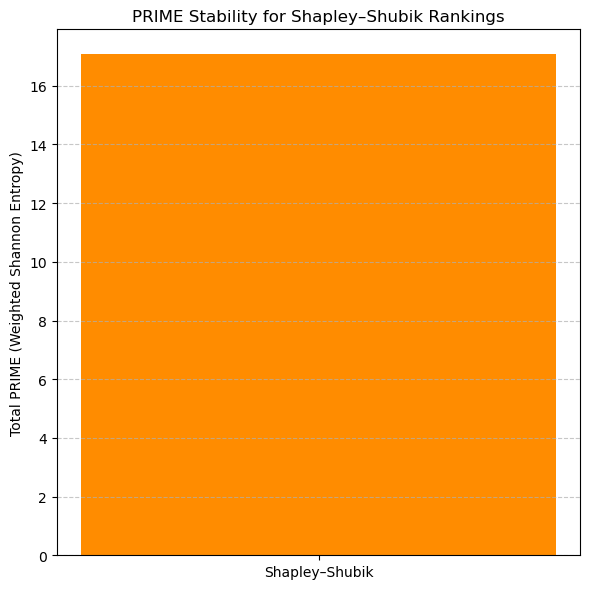

In [27]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import math
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from tqdm import tqdm  # Optional: for progress bar

# Parameters
num_permutations = 20
num_shapley_samples = 1000  # Number of random permutations
accuracy_threshold = 0.5    # Lowered threshold for better sensitivity

ss_rankings = []
print("\n[PRIME - Shapley–Shubik] Starting randomized permutations for stability calculation...")
start_time = time.time()

for perm in tqdm(range(num_permutations), desc="Permutations"):
    X_test_perm = X_test.copy()

    # Permute each feature individually
    for feature in features:
        X_test_perm[feature] = np.random.permutation(X_test_perm[feature])

    def compute_accuracy(subset):
        subset = list(subset)
        if not subset:
            return 0.0
        model = LogisticRegression(solver='liblinear')
        model.fit(X_train[subset], y_train)
        preds = model.predict(X_test_perm[subset])
        return accuracy_score(y_test, preds)

    # Shapley-Shubik approximation
    ss_counts = {f: 0 for f in features}
    sampled_perms = [np.random.permutation(features).tolist() for _ in range(num_shapley_samples)]

    for p in sampled_perms:
        subset = set()
        for f in p:
            prev_acc = compute_accuracy(subset)
            subset.add(f)
            curr_acc = compute_accuracy(subset)

            if np.isnan(curr_acc) or np.isnan(prev_acc):
                continue

            if prev_acc < accuracy_threshold <= curr_acc:
                ss_counts[f] += 1
                break

    total_counts = sum(ss_counts.values())
    if total_counts == 0:
        print(f"Warning: Warning: No features crossed threshold for permutation {perm+1}")
        ss_index = {f: 0.0 for f in features}
    else:
        ss_index = {f: ss_counts[f] / total_counts for f in features}

    print(f"Permutation {perm+1} SS Index: {ss_index}")
    ss_ranking = sorted(ss_index, key=ss_index.get, reverse=True)
    ss_rankings.append(ss_ranking)

# Check ranking diversity
unique_rankings = len(set(tuple(r) for r in ss_rankings))
print(f"\nTotal unique Shapley–Shubik rankings: {unique_rankings}/{num_permutations}")

def explicit_prime(rankings, features):
    rank_counts = {f: np.zeros(len(features)) for f in features}

    for ranking in rankings:
        for position, feat in enumerate(ranking):
            rank_counts[feat][position] += 1

    total_entropy = 0.0
    for feat in features:
        freq = rank_counts[feat]
        total_wp = np.sum(freq)
        if total_wp == 0:
            print(f"Warning: Skipping entropy for feature {feat} due to zero frequency")
            continue

        normalized_wp = freq / total_wp
        if np.all(normalized_wp < 1e-9):
            continue

        entropy_feat = -np.sum(normalized_wp * np.log2(normalized_wp + 1e-9))
        total_entropy += entropy_feat

    return total_entropy

ss_total_prime = explicit_prime(ss_rankings, features)

print("\n[Final Results] PRIME Stability (Shapley–Shubik with Sampling):")
print(f"Shapley–Shubik PRIME: {ss_total_prime:.6f}")
print(f"Total Execution Time: {time.time() - start_time:.2f} seconds")

plt.figure(figsize=(6, 6))
plt.bar(['Shapley–Shubik'], [ss_total_prime], color='darkorange')
plt.ylabel('Total PRIME (Weighted Shannon Entropy)')
plt.title('PRIME Stability for Shapley–Shubik Rankings')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

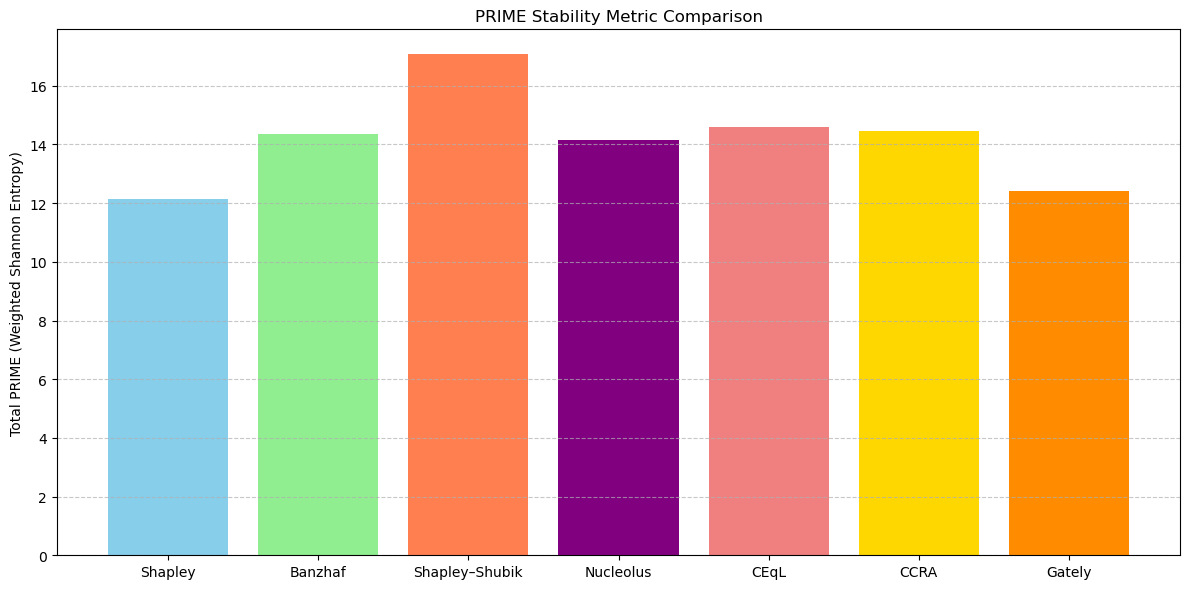

In [ ]:
import matplotlib.pyplot as plt

methods = ['Shapley', 'Banzhaf','Shapley–Shubik', 'Nucleolus','CEqL', 'CCRA', 'Gately']
prime_values = [12.152556,14.344623,17.069941,14.160309,14.593607,14.446727,12.407751]

# Define unique colors for each method
colors = ['skyblue', 'lightgreen', 'coral', 'purple', 'lightcoral', 'gold', 'darkorange']

# Plotting
plt.figure(figsize=(12, 6))
plt.bar(methods, prime_values, color=colors)
plt.ylabel("Total PRIME (Weighted Shannon Entropy)")
plt.title("PRIME Stability Metric Comparison")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

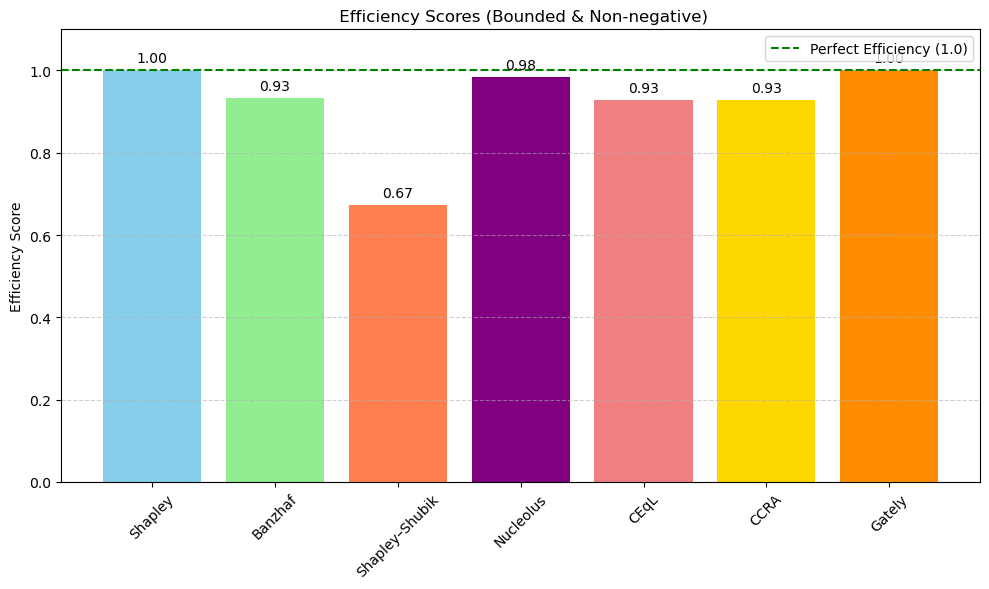

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Cooperative game values
v_grand_coalition = 0.75375
v_empty_set = 0.49875
v_total_shapley_banzhaf = v_grand_coalition - v_empty_set
v_total_others = v_grand_coalition

# Feature allocations
shapley_values = np.array([0.089455, -0.001440, 0.059122, -0.003920, 0.072372, 0.047497, -0.008086])
banzhaf_values = np.array([0.079648, 0.001680, 0.053633, -0.001094, 0.066875, 0.039570, -0.002383])
shapley_shubik_index = np.array([0.310317, 0.026190, 0.028571, 0.002381, 0.322222, 0.310317, 0.000000])
nucleolus_values = np.array([0.090867, 0.065056, 0.118282, 0.107679, 0.148468, 0.113147, 0.122685])
ceql_allocations = np.array([0.1675, 0.0112, 0.1412, 0.0237, 0.1725, 0.1687, 0.0150])
ccra_allocations = np.array([0.1112, 0.0852, 0.1069, 0.0873, 0.1121, 0.1115, 0.0858])
gately_allocations = np.array([0.1731, 0.0843, 0.1278, 0.0747, 0.1317, 0.0995, 0.0627])

# Dictionary of all methods with expected totals
methods = {
    "Shapley": (shapley_values, v_total_shapley_banzhaf),
    "Banzhaf": (banzhaf_values, v_total_shapley_banzhaf),
    "Shapley–Shubik": (shapley_shubik_index, v_total_others),
    "Nucleolus": (nucleolus_values, v_total_others),
    "CEqL": (ceql_allocations, v_total_others),
    "CCRA": (ccra_allocations, v_total_others),
    "Gately": (gately_allocations, v_total_others)
}

# Compute efficiency scores using the improved formula
efficiency_scores = {}
for name, (values, expected_sum) in methods.items():
    actual_sum = np.sum(values)
    efficiency_score = 1 - abs((actual_sum / expected_sum) - 1)
    efficiency_scores[name] = round(efficiency_score, 6)

# Plotting
methods_ordered = list(efficiency_scores.keys())
scores_ordered = list(efficiency_scores.values())

colors = ['skyblue', 'lightgreen', 'coral', 'purple', 'lightcoral', 'gold', 'darkorange']
plt.figure(figsize=(10, 6))
bars = plt.bar(methods_ordered, scores_ordered, color=colors)
plt.axhline(1.0, color='green', linestyle='--', label='Perfect Efficiency (1.0)')
plt.ylabel("Efficiency Score")
plt.title(" Efficiency Scores (Bounded & Non-negative)")
plt.ylim(0, 1.1)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()

# Add labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.02, f"{height:.2f}", ha='center')

plt.tight_layout()
plt.show()

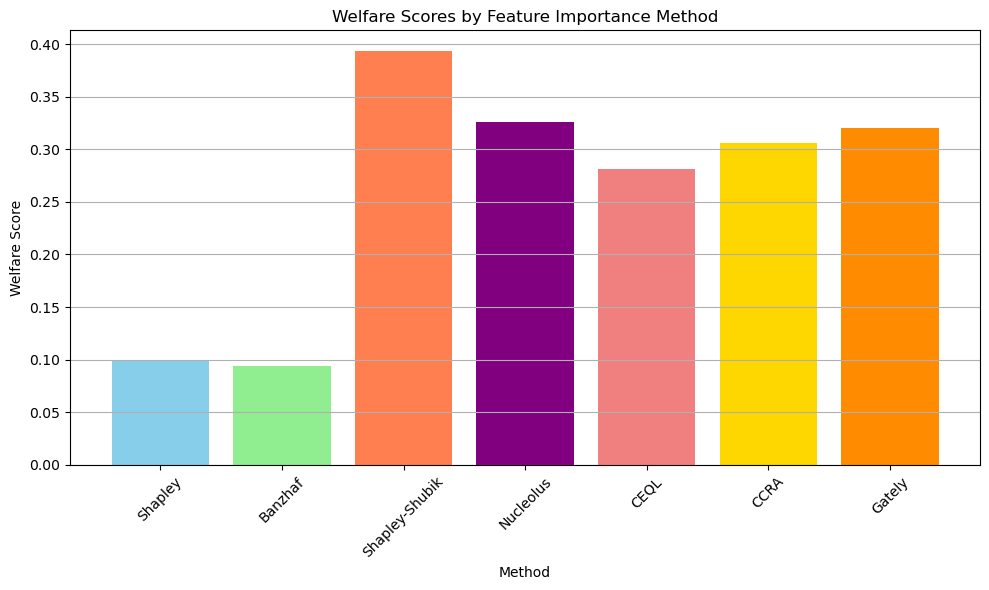

In [6]:
import numpy as np

# Provided feature importance vectors
methods = {
    "Shapley": np.array([0.089455, -0.001440, 0.059122, -0.003920, 0.072372, 0.047497, -0.008086]),
    "Banzhaf": np.array([0.079648, 0.001680, 0.053633, -0.001094, 0.066875, 0.039570, -0.002383]),
    "Shapley-Shubik": np.array([0.310317, 0.026190, 0.028571, 0.002381, 0.322222, 0.310317, 0.000000]),
    "Nucleolus": np.array([0.090867, 0.065056, 0.118282, 0.107679, 0.148468, 0.113147, 0.122685]),
    "CEQL": np.array([0.1675, 0.0112, 0.1412, 0.0237, 0.1725, 0.1687, 0.0150]),
    "CCRA": np.array([0.1112, 0.0852, 0.1069, 0.0873, 0.1121, 0.1115, 0.0858]),
    "Gately": np.array([0.1731, 0.0843, 0.1278, 0.0747, 0.1317, 0.0995, 0.0627]),
}

# Welfare maximization function
def welfare_maximization(feature_importances, alpha=0.4, beta=0.3, gamma=0.3):
    W_utilitarian = np.sum(feature_importances)
    W_egalitarian = -np.var(feature_importances)
    W_rawlsian = np.min(feature_importances)
    W = alpha * W_utilitarian + beta * W_egalitarian + gamma * W_rawlsian
    return W, W_utilitarian, W_egalitarian, W_rawlsian

# Compute welfare scores for all methods
welfare_results = []
for method, fi in methods.items():
    W, U, E, R = welfare_maximization(fi)
    welfare_results.append({
        "Method": method,
        "Welfare Score": W,
        "Utilitarian": U,
        "Egalitarian": E,
        "Rawlsian": R
    })

import pandas as pd
df = pd.DataFrame(welfare_results)


import matplotlib.pyplot as plt
colors = ['skyblue', 'lightgreen', 'coral', 'purple', 'lightcoral', 'gold', 'darkorange']
# Plot Welfare Scores
plt.figure(figsize=(10, 6))
plt.bar(df["Method"], df["Welfare Score"],color=colors)
plt.xlabel("Method")
plt.ylabel("Welfare Score")
plt.title("Welfare Scores by Feature Importance Method")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

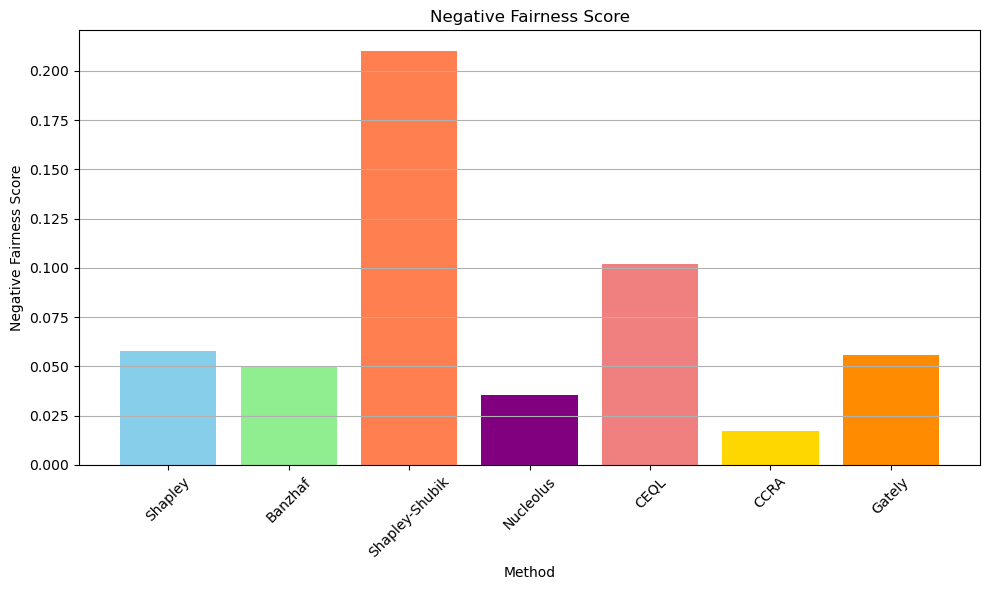

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Step 1: Load dataset
df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

# Step 2: Clean the dataset - convert 'Acidity' to numeric
df['Acidity'] = pd.to_numeric(df['Acidity'], errors='coerce')
df_cleaned = df.dropna(subset=['Acidity'])

# Step 3: Select numeric feature columns
feature_columns = ['Size', 'Weight', 'Sweetness', 'Crunchiness', 'Juiciness', 'Ripeness', 'Acidity']
feature_data = df_cleaned[feature_columns]

# Step 4: Normalize feature data
scaler = StandardScaler()
normalized_data = scaler.fit_transform(feature_data)

# Step 5: Transpose and apply KMeans clustering to feature vectors
feature_vectors = normalized_data.T
kmeans = KMeans(n_clusters=3, random_state=42).fit(feature_vectors)

# Step 6: Group features based on cluster labels
similar_groups = {}
for idx, label in enumerate(kmeans.labels_):
    similar_groups.setdefault(label, []).append(idx)

# Step 7: Generate all unique pairs within each cluster
similar_feature_pairs = []
for group in similar_groups.values():
    if len(group) > 1:
        for i in range(len(group)):
            for j in range(i + 1, len(group)):
                similar_feature_pairs.append((group[i], group[j]))

# Step 8: Feature importance values (given)
importance_methods = {
    "Shapley": np.array([0.089455, -0.001440, 0.059122, -0.003920, 0.072372, 0.047497, -0.008086]),
    "Banzhaf": np.array([0.079648, 0.001680, 0.053633, -0.001094, 0.066875, 0.039570, -0.002383]),
    "Shapley-Shubik": np.array([0.310317, 0.026190, 0.028571, 0.002381, 0.322222, 0.310317, 0.000000]),
    "Nucleolus": np.array([0.090867, 0.065056, 0.118282, 0.107679, 0.148468, 0.113147, 0.122685]),
    "CEQL": np.array([0.1675, 0.0112, 0.1412, 0.0237, 0.1725, 0.1687, 0.0150]),
    "CCRA": np.array([0.1112, 0.0852, 0.1069, 0.0873, 0.1121, 0.1115, 0.0858]),
    "Gately": np.array([0.1731, 0.0843, 0.1278, 0.0747, 0.1317, 0.0995, 0.0627]),
}

# Step 9: Define fairness metric
def compute_fairness(importance_array, pairs):
    diffs = [abs(importance_array[i] - importance_array[j]) for i, j in pairs]
    return np.mean(diffs)

# Step 10: Compute fairness scores for all methods
fairness_scores = []
for method, values in importance_methods.items():
    score = compute_fairness(values, similar_feature_pairs)
    fairness_scores.append({
        "Method": method,
        "Fairness Score (Lower is Fairer)": score
    })

# Display result
fairness_df = pd.DataFrame(fairness_scores)

import matplotlib.pyplot as plt
colors = ['skyblue', 'lightgreen', 'coral', 'purple', 'lightcoral', 'gold', 'darkorange']
# Create bar plot of fairness scores
plt.figure(figsize=(10, 6))
plt.bar(fairness_df["Method"], fairness_df["Fairness Score (Lower is Fairer)"], color=colors)
plt.title("Negative Fairness Score")
plt.xlabel("Method")
plt.ylabel("Negative Fairness Score")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

           Method  Relative Deviation from Mean Allocation
0         Shapley                                 0.001398
1         Banzhaf                                 0.001026
2  Shapley-Shubik                                 0.022153
3       Nucleolus                                 0.000587
4            CEQL                                 0.005309
5            CCRA                                 0.000148
6          Gately                                 0.001284


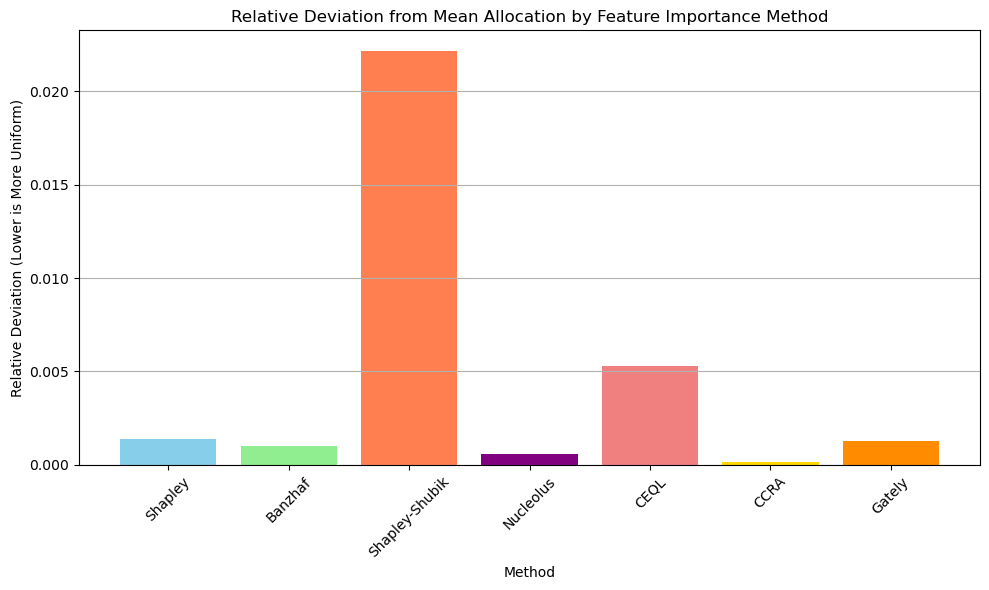

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load dataset
df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")

# Step 2: Clean the dataset - convert 'Acidity' to numeric
df['Acidity'] = pd.to_numeric(df['Acidity'], errors='coerce')
df_cleaned = df.dropna(subset=['Acidity'])

# Step 3: Feature importance values from different methods
importance_methods = {
    "Shapley": np.array([0.089455, -0.001440, 0.059122, -0.003920, 0.072372, 0.047497, -0.008086]),
    "Banzhaf": np.array([0.079648, 0.001680, 0.053633, -0.001094, 0.066875, 0.039570, -0.002383]),
    "Shapley-Shubik": np.array([0.310317, 0.026190, 0.028571, 0.002381, 0.322222, 0.310317, 0.000000]),
    "Nucleolus": np.array([0.090867, 0.065056, 0.118282, 0.107679, 0.148468, 0.113147, 0.122685]),
    "CEQL": np.array([0.1675, 0.0112, 0.1412, 0.0237, 0.1725, 0.1687, 0.0150]),
    "CCRA": np.array([0.1112, 0.0852, 0.1069, 0.0873, 0.1121, 0.1115, 0.0858]),
    "Gately": np.array([0.1731, 0.0843, 0.1278, 0.0747, 0.1317, 0.0995, 0.0627]),
}

# Step 4: Define the Relative Fairness Deviation function
def compute_relative_fairness_deviation(importance_array):
    mean_phi = np.mean(importance_array)
    deviation = np.mean([(phi - mean_phi) ** 2 for phi in importance_array])
    return deviation

# Step 5: Compute the metric for all methods
relative_deviation_scores = []
for method, values in importance_methods.items():
    score = compute_relative_fairness_deviation(values)
    relative_deviation_scores.append({
        "Method": method,
        "Relative Deviation from Mean Allocation": score
    })

# Step 6: Display results in table
relative_deviation_df = pd.DataFrame(relative_deviation_scores)
print(relative_deviation_df)
colors = ['skyblue', 'lightgreen', 'coral', 'purple', 'lightcoral', 'gold', 'darkorange']
# Step 7: Plot the results
plt.figure(figsize=(10, 6))
plt.bar(relative_deviation_df["Method"], relative_deviation_df["Relative Deviation from Mean Allocation"],color=colors)
plt.title("Relative Deviation from Mean Allocation by Feature Importance Method")
plt.xlabel("Method")
plt.ylabel("Relative Deviation (Lower is More Uniform)")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

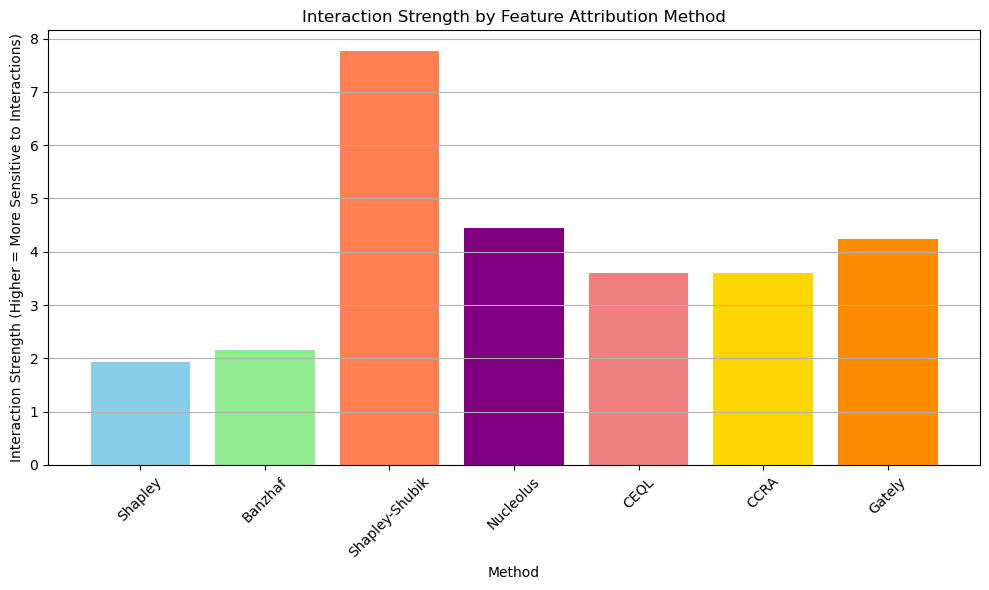

In [9]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")
df['Acidity'] = pd.to_numeric(df['Acidity'], errors='coerce')
df = df.dropna(subset=['Acidity'])

# Define features and target
feature_columns = ['Size', 'Weight', 'Sweetness', 'Crunchiness', 'Juiciness', 'Ripeness', 'Acidity']
X = df[feature_columns]
y = (df['Quality'] == 'good').astype(int)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 1: Compute ϕᵢ^ind using accuracy with one feature
def compute_independent_contributions(model_class, X_train, y_train, X_test, y_test):
    v_empty = 0.5  # baseline accuracy of random guessing
    independent_scores = []
    for feature in X_train.columns:
        model = model_class()
        model.fit(X_train[[feature]], y_train)
        y_pred = model.predict(X_test[[feature]])
        acc = accuracy_score(y_test, y_pred)
        independent_scores.append(acc - v_empty)
    return np.array(independent_scores)

phi_ind = compute_independent_contributions(LogisticRegression, X_train, y_train, X_test, y_test)

importance_methods = {
    "Shapley": np.array([0.089455, -0.001440, 0.059122, -0.003920, 0.072372, 0.047497, -0.008086]),
    "Banzhaf": np.array([0.079648, 0.001680, 0.053633, -0.001094, 0.066875, 0.039570, -0.002383]),
    "Shapley-Shubik": np.array([0.310317, 0.026190, 0.028571, 0.002381, 0.322222, 0.310317, 0.000000]),
    "Nucleolus": np.array([0.090867, 0.065056, 0.118282, 0.107679, 0.148468, 0.113147, 0.122685]),
    "CEQL": np.array([0.1675, 0.0112, 0.1412, 0.0237, 0.1725, 0.1687, 0.0150]),
    "CCRA": np.array([0.1112, 0.0852, 0.1069, 0.0873, 0.1121, 0.1115, 0.0858]),
    "Gately": np.array([0.1731, 0.0843, 0.1278, 0.0747, 0.1317, 0.0995, 0.0627]),
}

# Step 3: Compute proxy interaction strength
interaction_scores = []
for method, phi in importance_methods.items():
    interaction_strength = 0
    for i in range(len(phi)):
        for j in range(len(phi)):
            if i != j:
                term = abs((phi[i] + phi[j]) - (phi_ind[i] + phi_ind[j]))
                interaction_strength += term
    interaction_scores.append({"Method": method, "Interaction Strength": interaction_strength})

colors = ['skyblue', 'lightgreen', 'coral', 'purple', 'lightcoral', 'gold', 'darkorange']
# Step 4: Visualize
interaction_df = pd.DataFrame(interaction_scores)
plt.figure(figsize=(10, 6))
plt.bar(interaction_df["Method"], interaction_df["Interaction Strength"],color=colors)
plt.title("Interaction Strength by Feature Attribution Method")
plt.xlabel("Method")
plt.ylabel("Interaction Strength (Higher = More Sensitive to Interactions)")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

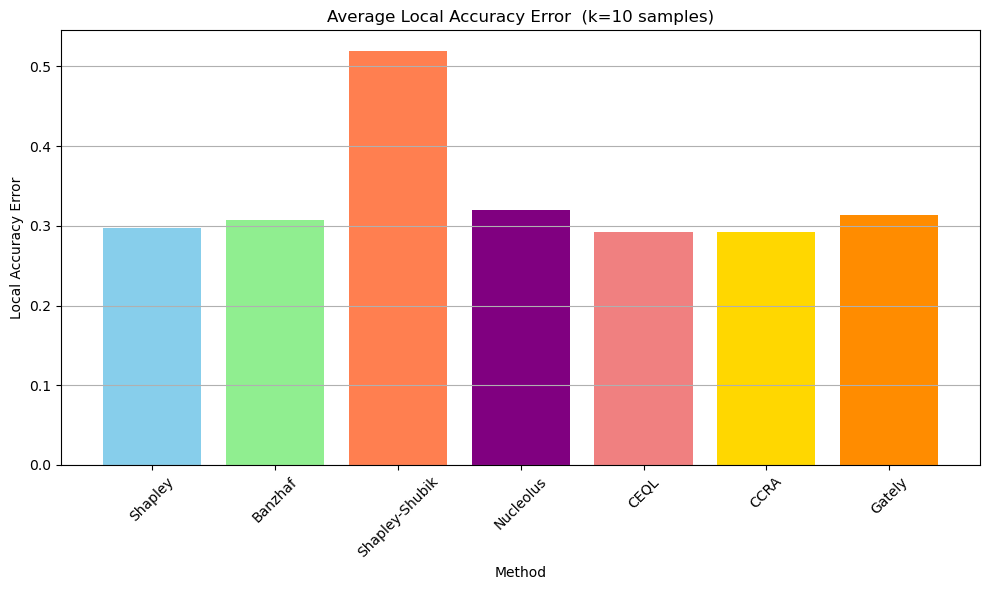

In [10]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Load and clean dataset
df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")
df['Acidity'] = pd.to_numeric(df['Acidity'], errors='coerce')
df = df.dropna(subset=['Acidity'])

# Prepare features and target
feature_columns = ['Size', 'Weight', 'Sweetness', 'Crunchiness', 'Juiciness', 'Ripeness', 'Acidity']
X = df[feature_columns]
y = (df['Quality'] == 'good').astype(int)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Define number of test samples to evaluate local accuracy on
k = 10

# Select k test samples
X_test_sample = X_test.iloc[:k]
f_x_list = model.predict_proba(X_test_sample)[:, 1]  # predicted probabilities for class "good"

# Define method attribution vectors (same static vector per method)
importance_methods = {
    "Shapley": np.array([0.089455, -0.001440, 0.059122, -0.003920, 0.072372, 0.047497, -0.008086]),
    "Banzhaf": np.array([0.079648, 0.001680, 0.053633, -0.001094, 0.066875, 0.039570, -0.002383]),
    "Shapley-Shubik": np.array([0.310317, 0.026190, 0.028571, 0.002381, 0.322222, 0.310317, 0.000000]),
    "Nucleolus": np.array([0.090867, 0.065056, 0.118282, 0.107679, 0.148468, 0.113147, 0.122685]),
    "CEQL": np.array([0.1675, 0.0112, 0.1412, 0.0237, 0.1725, 0.1687, 0.0150]),
    "CCRA": np.array([0.1112, 0.0852, 0.1069, 0.0873, 0.1121, 0.1115, 0.0858]),
    "Gately": np.array([0.1731, 0.0843, 0.1278, 0.0747, 0.1317, 0.0995, 0.0627]),
}

# Compute average local accuracy error for each method across k samples
local_accuracy_scores = []
for method, phi in importance_methods.items():
    local_errors = [abs(f_x - np.sum(phi)) for f_x in f_x_list]
    avg_error = np.mean(local_errors)
    local_accuracy_scores.append({
        "Method": method,
        "Avg Local Accuracy Error (k=10)": avg_error
    })

# Create DataFrame
local_accuracy_df = pd.DataFrame(local_accuracy_scores)
import matplotlib.pyplot as plt
colors = ['skyblue', 'lightgreen', 'coral', 'purple', 'lightcoral', 'gold', 'darkorange']
# Plotting the average local accuracy error
plt.figure(figsize=(10, 6))
plt.bar(local_accuracy_df["Method"], local_accuracy_df["Avg Local Accuracy Error (k=10)"],color=colors)
plt.title("Average Local Accuracy Error  (k=10 samples)")
plt.xlabel("Method")
plt.ylabel("Local Accuracy Error")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [3]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import itertools
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Load and preprocess dataset
df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")
df = df.drop('A_id', axis=1)
for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

X = df.drop(columns=["Quality"])
Y = df["Quality"]
feature_names = list(X.columns)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# Fit logistic regression
X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(X_test)
model = sm.Logit(Y_train, X_train_const).fit(disp=0)
X_test_array = X_test.values

# True Shapley per-instance function
def compute_true_shapley_phi(x_instance, model, feature_names):
    n = len(feature_names)
    phi = np.zeros(n)
    factorial = np.math.factorial
    for i, feature in enumerate(feature_names):
        marginal_contributions = []
        other_features = [f for f in feature_names if f != feature]
        for r in range(n):
            for subset in itertools.combinations(other_features, r):
                subset = list(subset)
                x_S = np.zeros_like(x_instance)
                for f in subset:
                    idx = feature_names.index(f)
                    x_S[idx] = x_instance[idx]
                x_S_input = sm.add_constant(pd.DataFrame([x_S], columns=feature_names), has_constant='add')
                f_S = model.predict(x_S_input)[0]
                x_S_i = x_S.copy()
                x_S_i[i] = x_instance[i]
                x_S_i_input = sm.add_constant(pd.DataFrame([x_S_i], columns=feature_names), has_constant='add')
                f_S_i = model.predict(x_S_i_input)[0]
                weight = (factorial(len(subset)) * factorial(n - len(subset) - 1)) / factorial(n)
                marginal_contributions.append(weight * (f_S_i - f_S))
        phi[i] = sum(marginal_contributions)
    return phi

# Banzhaf per-instance function
def compute_banzhaf_phi(x_instance, model, feature_names):
    n = len(feature_names)
    contributions = {feature: [] for feature in feature_names}
    for feature in feature_names:
        other_features = [f for f in feature_names if f != feature]
        subsets = itertools.chain.from_iterable(itertools.combinations(other_features, r) for r in range(n))
        for subset in subsets:
            mask = np.array([1 if fname in subset else 0 for fname in feature_names])
            x_subset = x_instance * mask
            x_with = x_subset.copy()
            x_with[feature_names.index(feature)] = x_instance[feature_names.index(feature)]
            x_input_with = sm.add_constant(pd.DataFrame([x_with], columns=feature_names), has_constant='add')
            x_input_without = sm.add_constant(pd.DataFrame([x_subset], columns=feature_names), has_constant='add')
            pred_with = model.predict(x_input_with)[0]
            pred_without = model.predict(x_input_without)[0]
            contributions[feature].append(pred_with - pred_without)
    return np.array([np.mean(contributions[f]) for f in feature_names])

# Infidelity metric
def compute_infidelity(f_x, phi, x, model, feature_names, num_perturbations=10):
    errors = []
    for _ in range(num_perturbations):
        delta = np.random.normal(0, 0.1, size=len(feature_names))
        x_perturbed = x - delta
        x_input_perturbed = sm.add_constant(pd.DataFrame([x_perturbed], columns=feature_names), has_constant='add')
        f_x_perturbed = model.predict(x_input_perturbed)[0]
        phi_dot_delta = np.dot(phi, delta)
        errors.append((f_x - f_x_perturbed - phi_dot_delta) ** 2)
    return np.mean(errors)

num_samples = 10
infidelity_shapley, infidelity_banzhaf = [], []

for i in range(num_samples):
    x = X_test_array[i]
    x_input = sm.add_constant(pd.DataFrame([x], columns=feature_names), has_constant='add')
    f_x_i = model.predict(x_input)[0]

    phi_shapley = compute_true_shapley_phi(x, model, feature_names)
    infidelity_shapley.append(compute_infidelity(f_x_i, phi_shapley, x, model, feature_names))

    phi_banzhaf = compute_banzhaf_phi(x, model, feature_names)
    infidelity_banzhaf.append(compute_infidelity(f_x_i, phi_banzhaf, x, model, feature_names))

# Average results
avg_shapley_inf = np.mean(infidelity_shapley)
avg_banzhaf_inf = np.mean(infidelity_banzhaf)
print(avg_shapley_inf)
print(avg_banzhaf_inf)

0.0018834021100506305
0.0024657118712723795


In [10]:
# Add Shapley-Shubik index per-instance attribution function
from random import sample
perms = sample(list(itertools.permutations(feature_names)), 300)

def compute_shapley_shubik_phi(x_instance, model, feature_names, threshold=0.6):
    from itertools import permutations
    n = len(feature_names)
    pivotal_counts = {f: 0 for f in feature_names}
    perms = sample(list(itertools.permutations(feature_names)), 300)
    total = len(perms)

    for perm in perms:
        subset = set()
        for f in perm:
            x_sub = np.zeros_like(x_instance)
            for s in subset:
                idx = feature_names.index(s)
                x_sub[idx] = x_instance[idx]
            acc_prev = model.predict(sm.add_constant(pd.DataFrame([x_sub], columns=feature_names), has_constant='add'))[0]

            subset.add(f)
            x_sub_next = np.zeros_like(x_instance)
            for s in subset:
                idx = feature_names.index(s)
                x_sub_next[idx] = x_instance[idx]
            acc_curr = model.predict(sm.add_constant(pd.DataFrame([x_sub_next], columns=feature_names), has_constant='add'))[0]

            if np.isnan(acc_prev) or np.isnan(acc_curr):
                continue

            if acc_prev < threshold <= acc_curr:
                pivotal_counts[f] += 1
                break

    return np.array([pivotal_counts[f] / total for f in feature_names])

# Compute infidelity for Shapley-Shubik
infidelity_shapley_shubik = []
for i in range(num_samples):
    x = X_test_array[i]
    x_input = sm.add_constant(pd.DataFrame([x], columns=feature_names), has_constant='add')
    f_x_i = model.predict(x_input)[0]

    phi_shubik = compute_shapley_shubik_phi(x, model, feature_names, threshold=0.6)
    infidelity_shapley_shubik.append(compute_infidelity(f_x_i, phi_shubik, x, model, feature_names))

avg_shubik_inf = np.mean(infidelity_shapley_shubik)
avg_shubik_inf

0.0006638627324757014

In [ ]:
def compute_nucleolus_phi(x_instance, model, feature_names, accuracy_values):
    total_value = sum(accuracy_values[frozenset({f})] for f in feature_names)
    full_coalition_value = accuracy_values[frozenset(feature_names)]

    x = {
        feature: (accuracy_values[frozenset({feature})] / total_value) * full_coalition_value
        for feature in feature_names
    }

    def compute_excess(S, x_values):
        subset_excess = []
        for r in range(1, len(S) + 1):
            for T in itertools.combinations(S, r):
                T = frozenset(T)
                if T in accuracy_values and T:
                    excess = accuracy_values[T] - sum(x_values.get(f, 0) for f in T)
                    subset_excess.append(excess)
        return max(subset_excess) if subset_excess else 0

    # Coalition values for excess computation
    excess_values = {S: compute_excess(S, x) for S in accuracy_values if S}

    max_iterations = 1000
    iteration = 0
    while any(excess_values[S] > accuracy_values[S] / (len(S) + 1) for S in excess_values) and iteration < max_iterations:
        for S in excess_values:
            for feature in S:
                x[feature] += (accuracy_values[S] - sum(x.get(f, 0) for f in S)) / (len(S) + 1)
            excess_values[S] = compute_excess(S, x)
        iteration += 1

    return np.array([x[f] for f in feature_names])

# Now use Nucleolus attributions to compute infidelity
infidelity_nucleolus = []
for i in range(num_samples):
    x = X_test_array[i]
    x_input = sm.add_constant(pd.DataFrame([x], columns=feature_names), has_constant='add')
    f_x_i = model.predict(x_input)[0]

    phi_nucleolus = compute_nucleolus_phi(x, model, feature_names, accuracy_values)
    infidelity_nucleolus.append(compute_infidelity(f_x_i, phi_nucleolus, x, model, feature_names))

avg_nucleolus_inf = np.mean(infidelity_nucleolus)
avg_nucleolus_inf

0.0008576334114934884

In [12]:
import numpy as np
import pandas as pd
import math
from itertools import permutations
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import statsmodels.api as sm

# Load dataset
df = pd.read_csv(r"../datasets/apple_quality/apple_quality.csv")
df['Acidity'] = pd.to_numeric(df['Acidity'], errors='coerce')
if 'A_id' in df.columns:
    df = df.drop('A_id', axis=1)
for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df['Quality'] = df['Quality'].map({'bad': 0, 'good': 1})

# Split data
X = df.drop(columns=['Quality'])
Y = df['Quality']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
feature_names = X.columns.tolist()
X_test_array = X_test.values

# Compute claims (accuracy of each feature individually)
claims = []
for feature in feature_names:
    X_train_single = X_train[[feature]]
    X_test_single = X_test[[feature]]
    model_single = LogisticRegression(solver='liblinear')
    model_single.fit(X_train_single, Y_train)
    y_pred = model_single.predict(X_test_single)
    c_i = accuracy_score(Y_test, y_pred)
    claims.append(c_i)

# CEqL allocation function
def compute_ceql(claims, E):
    c_array = np.array(claims, dtype=float)
    total_claims = np.sum(c_array)
    if total_claims <= E:
        return c_array.tolist()
    lo, hi = 0.0, np.max(c_array)
    for _ in range(100):
        mid = (lo + hi) / 2.0
        current_sum = np.sum(np.maximum(0, c_array - mid))
        if current_sum > E:
            lo = mid
        else:
            hi = mid
    r = (lo + hi) / 2.0
    return np.maximum(0, c_array - r).tolist()

# CCRA allocation function
def compute_ccra(claims, E):
    c_array = np.array(claims, dtype=float)
    n = len(c_array)
    V = np.zeros(n, dtype=float)
    all_indices = range(n)
    perm_count = math.factorial(n)
    for perm in permutations(all_indices):
        E_temp = E
        for idx in perm:
            award = min(c_array[idx], E_temp)
            V[idx] += award
            E_temp -= award
            if E_temp <= 0:
                break
    return (V / perm_count).tolist()

# Infidelity function
def compute_infidelity(f_x, phi, x, model, feature_names, num_perturbations=10):
    errors = []
    for _ in range(num_perturbations):
        delta = np.random.normal(0, 0.1, size=len(feature_names))
        x_perturbed = x - delta
        x_input_perturbed = sm.add_constant(pd.DataFrame([x_perturbed], columns=feature_names), has_constant='add')
        f_x_perturbed = model.predict(x_input_perturbed)[0]
        phi_dot_delta = np.dot(phi, delta)
        errors.append((f_x - f_x_perturbed - phi_dot_delta) ** 2)
    return np.mean(errors)

# Fit full logistic regression model for prediction
X_train_const = sm.add_constant(X_train)
model = sm.Logit(Y_train, X_train_const).fit(disp=0)

# Use an endowment value
E = 0.7
phi_ceql = np.array(compute_ceql(claims, E))
phi_ccra = np.array(compute_ccra(claims, E))

# Compute infidelity for CEqL and CCRA
num_samples = 10
infidelity_ceql, infidelity_ccra = [], []

for i in range(num_samples):
    x = X_test_array[i]
    x_input = sm.add_constant(pd.DataFrame([x], columns=feature_names), has_constant='add')
    f_x_i = model.predict(x_input)[0]
    infidelity_ceql.append(compute_infidelity(f_x_i, phi_ceql, x, model, feature_names))
    infidelity_ccra.append(compute_infidelity(f_x_i, phi_ccra, x, model, feature_names))

avg_ceql_inf = np.mean(infidelity_ceql)
avg_ccra_inf = np.mean(infidelity_ccra)
avg_ceql_inf, avg_ccra_inf

(0.0005193302926336881, 0.0004500821075723486)

In [13]:
# Define Gately allocation function
def compute_gately_allocation(X_train, X_test, y_train, y_test, features):
    def compute_accuracy(feature_subset):
        model = LogisticRegression(solver='liblinear')
        model.fit(X_train[feature_subset], y_train)
        y_pred = model.predict(X_test[feature_subset])
        return accuracy_score(y_test, y_pred)

    vN = compute_accuracy(features)
    v_single = {f: compute_accuracy([f]) for f in features}
    v_without = {f: compute_accuracy([col for col in features if col != f]) for f in features}

    n = len(features)
    numerator = (n - 1) * vN - sum(v_without[f] for f in features)
    denom = vN - sum(v_single[f] for f in features)
    if np.isclose(denom, 0):
        raise ValueError("The denominator is zero; cannot compute d*.")
    d_star = numerator / denom
    if np.isclose(d_star, -1):
        raise ValueError("d* is -1; the Gately point cannot be computed.")

    gately_allocation = {
        f: (vN - v_without[f] + d_star * v_single[f]) / (d_star + 1)
        for f in features
    }
    return np.array([gately_allocation[f] for f in features])

# Compute Gately allocation vector
phi_gately = compute_gately_allocation(X_train, X_test, Y_train, Y_test, feature_names)

# Compute infidelity for Gately
infidelity_gately = []
for i in range(num_samples):
    x = X_test_array[i]
    x_input = sm.add_constant(pd.DataFrame([x], columns=feature_names), has_constant='add')
    f_x_i = model.predict(x_input)[0]
    infidelity_gately.append(compute_infidelity(f_x_i, phi_gately, x, model, feature_names))

avg_gately_inf = np.mean(infidelity_gately)
avg_gately_inf

0.0005669627884670906

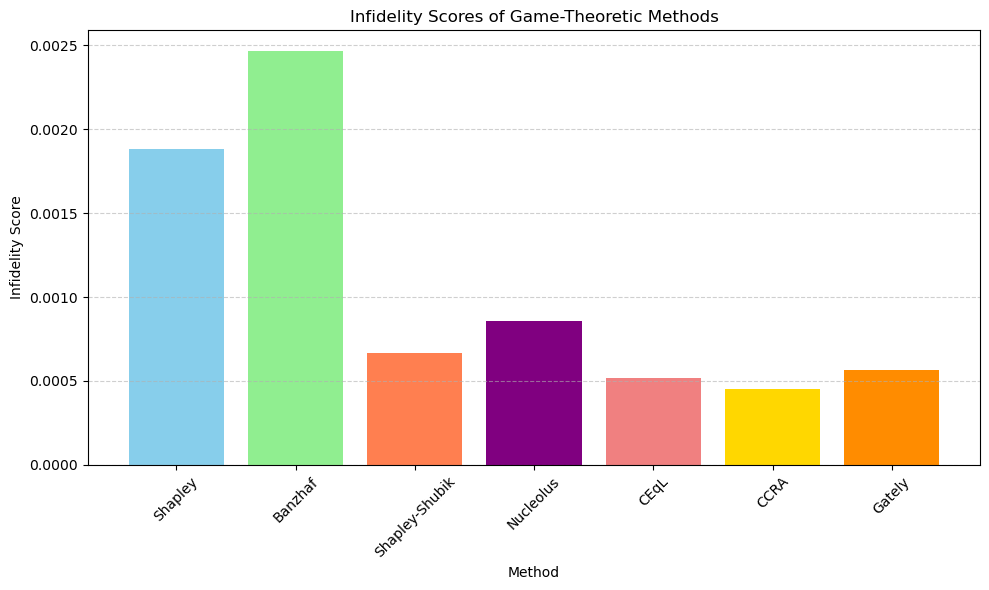

In [17]:
import matplotlib.pyplot as plt

# Method names and their corresponding infidelity scores
methods = ['Shapley', 'Banzhaf', 'Shapley-Shubik', 'Nucleolus', 'CEqL', 'CCRA', 'Gately']
infidelity_scores = [
    0.0018834021100506305,
    0.0024657118712723795,
    0.0006638627324757014,
    0.0008576334114934884,
    0.0005193302926336881,
    0.0004500821075723486,
    0.0005669627884670906
]
colors = ['skyblue', 'lightgreen', 'coral', 'purple', 'lightcoral', 'gold', 'darkorange']

# Plotting
plt.figure(figsize=(10, 6))
plt.bar(methods, infidelity_scores, color=colors)
plt.title("Infidelity Scores of Game-Theoretic Methods")
plt.ylabel("Infidelity Score")
plt.xlabel("Method")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

In [14]:
# Define Sensitivity metric
def compute_sensitivity(f_x, phi, x, model, feature_names, k=3):
    top_k_indices = np.argsort(np.abs(phi))[::-1][:k]
    x_masked = x.copy()
    for i in top_k_indices:
        x_masked[i] = 0  # mask top-k features by setting to zero
    x_input_masked = sm.add_constant(pd.DataFrame([x_masked], columns=feature_names), has_constant='add')
    f_x_masked = model.predict(x_input_masked)[0]
    return abs(f_x - f_x_masked)

# Compute Sensitivity@k for all methods
sensitivity_scores = {
    "Shapley": [],
    "Banzhaf": [],
    "Shapley-Shubik": [],
    "Nucleolus": [],
    "CEqL": [],
    "CCRA": [],
    "Gately": []
}

# Loop over test instances
for i in range(num_samples):
    x = X_test_array[i]
    x_input = sm.add_constant(pd.DataFrame([x], columns=feature_names), has_constant='add')
    f_x_i = model.predict(x_input)[0]

    phi_shapley = compute_true_shapley_phi(x, model, feature_names)
    phi_banzhaf = compute_banzhaf_phi(x, model, feature_names)
    phi_shubik = compute_shapley_shubik_phi(x, model, feature_names, threshold=0.6)
    phi_nucleolus = compute_nucleolus_phi(x, model, feature_names, accuracy_values)
    phi_ceql = np.array(compute_ceql(claims, E))
    phi_ccra = np.array(compute_ccra(claims, E))
    phi_gately = compute_gately_allocation(X_train, X_test, Y_train, Y_test, feature_names)

    sensitivity_scores["Shapley"].append(compute_sensitivity(f_x_i, phi_shapley, x, model, feature_names))
    sensitivity_scores["Banzhaf"].append(compute_sensitivity(f_x_i, phi_banzhaf, x, model, feature_names))
    sensitivity_scores["Shapley-Shubik"].append(compute_sensitivity(f_x_i, phi_shubik, x, model, feature_names))
    sensitivity_scores["Nucleolus"].append(compute_sensitivity(f_x_i, phi_nucleolus, x, model, feature_names))
    sensitivity_scores["CEqL"].append(compute_sensitivity(f_x_i, phi_ceql, x, model, feature_names))
    sensitivity_scores["CCRA"].append(compute_sensitivity(f_x_i, phi_ccra, x, model, feature_names))
    sensitivity_scores["Gately"].append(compute_sensitivity(f_x_i, phi_gately, x, model, feature_names))

# Compute average Sensitivity@k for each method
avg_sensitivity = {method: np.mean(scores) for method, scores in sensitivity_scores.items()}
avg_sensitivity

{'Shapley': 0.24004195470414538,
 'Banzhaf': 0.24004195470414538,
 'Shapley-Shubik': 0.23390374532732827,
 'Nucleolus': 0.07670544634553572,
 'CEqL': 0.23546318700504038,
 'CCRA': 0.23546318700504038,
 'Gately': 0.2532861050098022}

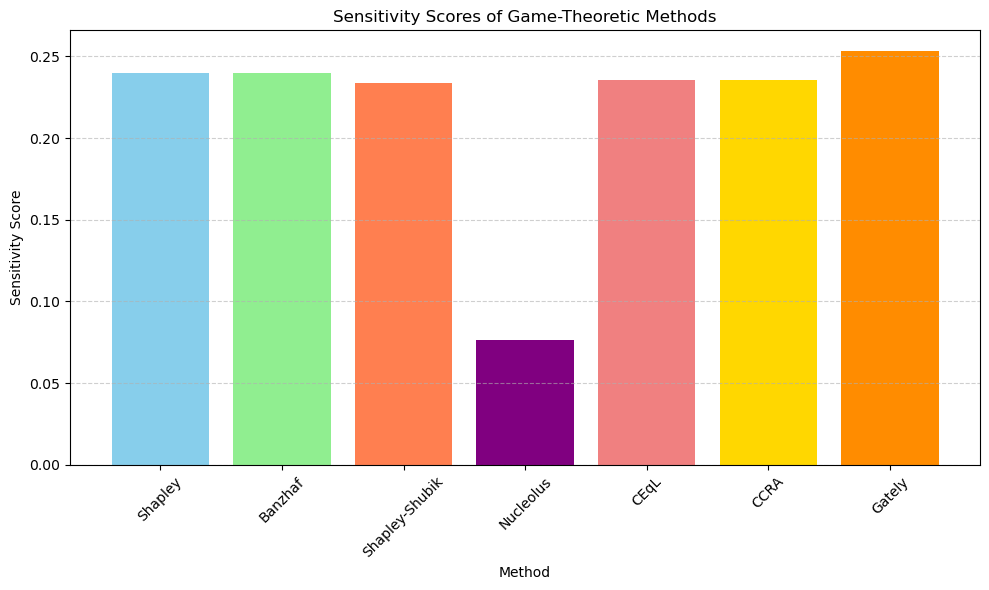

In [18]:
# Sensitivity scores for each method
sensitivity_scores = [
    0.24004195470414538,
    0.24004195470414538,
    0.23390374532732827,
    0.07670544634553572,
    0.23546318700504038,
    0.23546318700504038,
    0.2532861050098022
]

# Plotting
plt.figure(figsize=(10, 6))
plt.bar(methods, sensitivity_scores, color=colors)
plt.title("Sensitivity Scores of Game-Theoretic Methods")
plt.ylabel("Sensitivity Score")
plt.xlabel("Method")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

In [15]:
# Define Sufficiency metric
def compute_sufficiency(f_x, phi, x, model, feature_names, k=3):
    top_k_indices = np.argsort(np.abs(phi))[::-1][:k]
    x_retained = np.zeros_like(x)
    for i in top_k_indices:
        x_retained[i] = x[i]  # retain top-k features, mask the rest
    x_input_retained = sm.add_constant(pd.DataFrame([x_retained], columns=feature_names), has_constant='add')
    f_x_retained = model.predict(x_input_retained)[0]
    return abs(f_x - f_x_retained)

# Compute Sufficiency@k for all methods
sufficiency_scores = {
    "Shapley": [],
    "Banzhaf": [],
    "Shapley-Shubik": [],
    "Nucleolus": [],
    "CEqL": [],
    "CCRA": [],
    "Gately": []
}

for i in range(num_samples):
    x = X_test_array[i]
    x_input = sm.add_constant(pd.DataFrame([x], columns=feature_names), has_constant='add')
    f_x_i = model.predict(x_input)[0]

    phi_shapley = compute_true_shapley_phi(x, model, feature_names)
    phi_banzhaf = compute_banzhaf_phi(x, model, feature_names)
    phi_shubik = compute_shapley_shubik_phi(x, model, feature_names, threshold=0.6)
    phi_nucleolus = compute_nucleolus_phi(x, model, feature_names, accuracy_values)
    phi_ceql = np.array(compute_ceql(claims, E))
    phi_ccra = np.array(compute_ccra(claims, E))
    phi_gately = compute_gately_allocation(X_train, X_test, Y_train, Y_test, feature_names)

    sufficiency_scores["Shapley"].append(compute_sufficiency(f_x_i, phi_shapley, x, model, feature_names))
    sufficiency_scores["Banzhaf"].append(compute_sufficiency(f_x_i, phi_banzhaf, x, model, feature_names))
    sufficiency_scores["Shapley-Shubik"].append(compute_sufficiency(f_x_i, phi_shubik, x, model, feature_names))
    sufficiency_scores["Nucleolus"].append(compute_sufficiency(f_x_i, phi_nucleolus, x, model, feature_names))
    sufficiency_scores["CEqL"].append(compute_sufficiency(f_x_i, phi_ceql, x, model, feature_names))
    sufficiency_scores["CCRA"].append(compute_sufficiency(f_x_i, phi_ccra, x, model, feature_names))
    sufficiency_scores["Gately"].append(compute_sufficiency(f_x_i, phi_gately, x, model, feature_names))

# Compute average Sufficiency@k for each method
avg_sufficiency = {method: np.mean(scores) for method, scores in sufficiency_scores.items()}
avg_sufficiency

{'Shapley': 0.05921358379610629,
 'Banzhaf': 0.05921358379610629,
 'Shapley-Shubik': 0.27454644980121473,
 'Nucleolus': 0.22820117251852742,
 'CEqL': 0.15107639905219075,
 'CCRA': 0.15107639905219075,
 'Gately': 0.09264826707418636}

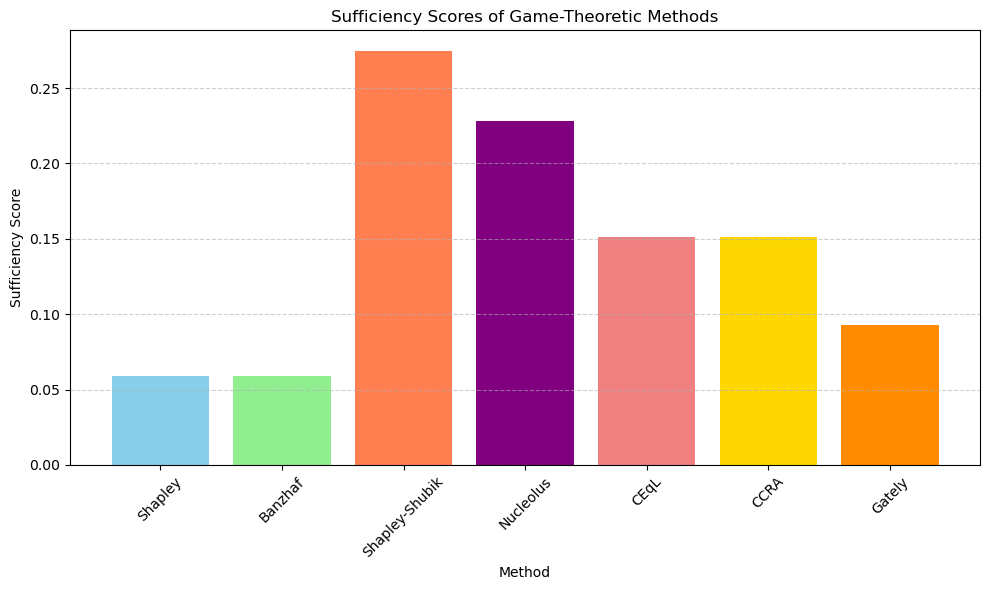

In [19]:
# Sufficiency scores for each method
sufficiency_scores = [
    0.05921358379610629,
    0.05921358379610629,
    0.27454644980121473,
    0.22820117251852742,
    0.15107639905219075,
    0.15107639905219075,
    0.09264826707418636
]

# Plotting
plt.figure(figsize=(10, 6))
plt.bar(methods, sufficiency_scores, color=colors)
plt.title("Sufficiency Scores of Game-Theoretic Methods")
plt.ylabel("Sufficiency Score")
plt.xlabel("Method")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()